<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/23_Adversarial_Attacks_Against_QML/QNN_AdversarialRobustness_Maouaki2024.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# AdvQuNN: adversarial robustness of quanvolutional neural networks (Maouaki et al., 2024) step by step

This notebook re-implements, runs and checks the experiments of

> Walid El Maouaki, Alberto Marchisio, Taoufik Said, Mohamed Bennai and Muhammad Shafique,
> "AdvQuNN: A Methodology for Analyzing the Adversarial Robustness of Quanvolutional Neural Networks",
> *IEEE International Conference on Quantum Software (QSW)* 2024, DOI [10.1109/QSW62656.2024.00033](https://doi.org/10.1109/qsw62656.2024.00033), arXiv:2403.05596v2.

**What the notebook does.** It builds the paper's *quanvolutional neural network* (QuNN): a fixed 4-qubit "quantum convolution" with a 2 x 2 kernel and stride 2
(angle encoding `RY(pi x)`, a parameterised circuit, Pauli-Z read-out of every qubit giving 4 output channels) followed by a trainable dense softmax head. It does this for the
**five Ansatz architectures** of the paper (no entanglement, ZZ full, ZZ linear, ZZ star, random), and builds the two classical comparison models (a `Conv2D` network and a
fully-connected network). Every model is trained on **50 images** of MNIST or Fashion-MNIST, then attacked in the white-box setting with **FGSM, PGD and MIM** over a wide range of
perturbation strengths epsilon (log scale, as in the paper), on 30 test images, repeated over independent trials. The notebook then redraws the paper's Figures 5 and 6, and
checks, claim by claim, whether the paper's statements about QuNN-vs-CNN robustness and about the influence of the Ansatz architecture are reproduced.

**How to run.** Open in Google Colab (badge above), choose a *CPU* runtime, and use *Runtime -> Run all*. `FAST_MODE = True` (3 trials, 5 attack iterations) takes a few minutes; `FAST_MODE = False`
(7 trials as in the paper, 10 attack iterations) takes roughly ten minutes on a CPU. Everything is simulated exactly (4 qubits per patch), so no quantum hardware, no IBM token and no Hugging Face token is needed
(MNIST / Fashion-MNIST are not gated; if the primary mirrors fail the notebook falls back to the Hugging Face copies and uses `HF_TOKEN` from the environment or from Colab *Settings -> Secrets* only if the reader has set one).

**What you get at the end.** Class distributions and 2-D projections of the real images, drawings of the executed circuits (one per architecture, checked against the NumPy simulator that does the heavy lifting), accuracy-vs-epsilon curves
for every model and attack, and a table of per-claim verdicts ("reproduced" / "not reached" / "exceeded" / "cannot be checked") with the paper's statements next to the numbers measured here.

## The paper in one page

**Problem.** Quantum neural networks can be fooled by adversarial examples like classical ones. Hybrid quantum-classical networks such as the *quanvolutional* neural network (QuNN, Henderson et al. 2020) replace the
convolution filter of a CNN by a small quantum circuit. Is a QuNN more robust than a CNN, and does the **design of the quantum circuit (the "Ansatz")** matter? The authors propose **AdvQuNN**, a methodology that sweeps Ansatz architectures and
attack types over a range of perturbation strengths.

**Model (Fig. 2, Fig. 4).** A 28 x 28 image is cut into 2 x 2 patches with stride 2. Each patch (4 pixels in [0, 1]) is **angle-encoded** with `RY(pi x_i)` on 4 qubits, a **parameterised unitary U(theta)** is applied, and the Pauli-Z expectation
`<Z>` of each qubit becomes one of 4 channels of a 14 x 14 feature map. The quantum filter is **not trained** (random parameters, "we opt for random initialization"); the feature map is flattened and fed to classical layers: for **MNIST** directly into a 10-way softmax,
for **Fashion-MNIST** through `Dropout(0.3) - Dense(32, relu) - Dropout(0.3) - Dense(64, relu) - Dense(10, softmax)`. The two classical models are a `Conv2D(4 filters, 2 x 2, stride 2, relu)` network with the same head, and a network of fully connected layers only.

**Ansatz architectures (Fig. 3).** (a) no entanglement: `Rot(a,b,c) = Rz(a) Ry(b) Rz(c)` on every qubit; (b) **ZZ full**: the same plus `exp(-i theta Z Z)` between all 6 qubit pairs (Rz angles theta13..theta18);
(c) **ZZ linear**: ZZ gates on the chain (3 pairs); (d) **ZZ star**: ZZ gates between qubit 1 and all others (3 pairs); (e) a **random** circuit.

**Training and attacks (Section IV-A).** 50 training samples, batch size 4, 30 epochs, Adam, learning rate 0.001, sparse categorical cross-entropy; white-box **FGSM, PGD and MIM** (Algorithms 1-3) on **30 test images**; epsilon from small to large
(FGSM 0 to 15, PGD and MIM 0 to 10, logarithmic axis); pixels clipped to [0, 1], so all epsilon above 1 look identical ("plateau", pointer 4 in Fig. 5a); **7 trials** per architecture, error bars.

**Claims that can be checked here.**
1. Under FGSM the classical models (CNN, DNN) collapse to near-zero accuracy at small epsilon, whereas the QuNN with the ZZ-full Ansatz "declines more gradually" and keeps **more than 0.6 accuracy at high epsilon** on MNIST (Fig. 5a).
2. The same holds for PGD (Fig. 5b); under MIM the picture is the same "with a slight decrease in accuracy in the QuNN" (Fig. 5c).
3. On Fashion-MNIST the classical models drop to zero at low epsilon, the QuNN "maintains an accuracy level around 0.4" (Fig. 6a-c).
4. Abstract: QuNNs reach "up to **60 %** higher robustness for MNIST and **40 %** for FMNIST" than classical convolutional networks.
5. MNIST (Fig. 6d-f): **ZZ full and ZZ star are the most robust** of the five architectures under all three attacks; no-entanglement and ZZ linear are better than the random architecture, which is "consistently" the worst.
6. Increasing entanglement from "no entanglement" to "full entanglement" improves resilience on MNIST (Section IV-D).
7. Fashion-MNIST (Fig. 6a): the **random architecture outperforms the others**, and the robustness ranking of the Ansatzes differs between the two datasets.
8. FGSM accuracy is exactly constant for epsilon >= 1 (pixel clipping, pointer 4).

### What follows the paper and what had to be chosen

The paper gives the model, the training recipe and the attack families, but not the random-circuit definition, the PGD/MIM hyper-parameters or the exact epsilon grid; the code is not public. Everything unspecified is marked `# CHOICE:` in the code.

| Item | Paper | This notebook |
|---|---|---|
| Quantum filter | 2 x 2 kernel, stride 2, 4 qubits, `RY(pi x)` angle encoding, `<Z>` on each qubit = 4 channels | same, PennyLane (`AngleEmbedding(pi x, rotation="Y")`, `Rot`, `CNOT-RZ-CNOT`, `expval(PauliZ)`); heavy lifting in an exact NumPy statevector simulator **asserted equal** to the PennyLane QNode |
| ZZ entanglers | `exp(-i theta Z Z)` drawn as `CNOT - Rz(theta) - CNOT` (Fig. 3b) | same: `CNOT - RZ(theta) - CNOT`, one free angle per pair (6 / 3 / 3 pairs for full / linear / star) |
| Quantum parameters | random initialisation, not trained; distribution not stated | uniform in [0, 2 pi), one fresh draw per trial (`# CHOICE`) |
| Random architecture (Fig. 3e) | "a random circuit", only 4 rotation gates are visible | 4 rotation gates (`RX`/`RY`/`RZ`, random qubit) and 2 `CNOT`s at random positions, a new circuit per trial (`# CHOICE`) |
| Classical models | Conv2D(4, 2x2, stride 2, relu) + same head; second model "fully connected layers only" | trainable `Conv2D` (Keras Glorot init, with bias) + head; DNN = `Flatten` + the same head on the 784 raw pixels (`# CHOICE`) |
| Head | MNIST: direct softmax; FMNIST: Dropout .3, Dense 32, Dropout .3, Dense 64, softmax (order read from Fig. 4) | same, written in NumPy (Keras Glorot init, Adam beta 0.9 / 0.999, eps 1e-7, inverted dropout) instead of Keras |
| Training set | 50 samples (batch 4, 30 epochs, lr 0.001); selection not stated | 50 class-balanced random images (5 per class) of the official training split, drawn anew in every trial (`# CHOICE`); no early stopping, no hyper-parameter tuning, so no validation split is needed |
| Test set | 30 images | 30 class-balanced random images (3 per class) of the official test split, drawn anew in every trial; with 30 images accuracy moves in steps of 0.033 |
| FGSM | Algorithm 1, epsilon 0 to 15 (log axis) | same; grid `0, 0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1, 3, 10, 15` (`# CHOICE`) |
| PGD | Algorithm 2 (k and alpha not given; the printed pseudo-code calls FGSM inside the loop without using its result) | standard Madry PGD: k steps of size `alpha = 2.5 eps / k`, projection onto the epsilon-ball and [0, 1], no random start (`# CHOICE`: k = 10, 5 in FAST_MODE) |
| MIM | Algorithm 3, decay factor mu not given | Dong et al. with mu = 1, same k and alpha as PGD, gradient normalised by its per-image L1 norm (`# CHOICE`) |
| Epsilon grid PGD / MIM | 0 to 10 | `0, 0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1, 3, 10` (`# CHOICE`) |
| Gradients | TensorFlow `GradientTape` through the quantum layer | exact analytic input gradient of the quanvolution layer (verified against finite differences below) |
| Trials | 7 | 7 (FAST_MODE: 3) |
| Quantum hardware | none (simulation) | none |

In [1]:
# --- installs, pinned to the versions this notebook was tested with. PennyLane draws the circuits and cross-checks the NumPy simulator.
# --- Colab already ships numpy, pandas, scikit-learn, matplotlib, scipy and requests.
import sys, importlib
IN_COLAB = "google.colab" in sys.modules
def _have(m):
    try:
        importlib.import_module(m); return True
    except Exception:
        return False
if IN_COLAB or not _have("pennylane"):
    !pip -q install "pennylane==0.45.1"
    # a runtime restart is normally NOT needed; if an import below fails, restart once and Run all again

In [2]:
# ----------------------------------------------- configuration: every tunable constant lives here -----------------------------------------------
SEED = 42
FAST_MODE = False            # True: a few minutes on a CPU (3 trials, 5 attack iterations); False: the paper's 7 trials and 10 attack iterations (about ten minutes)
IBM_TOKEN = ""              # not used: every circuit is simulated exactly (4 qubits per patch); kept for symmetry with the other notebooks

DATA_DIR = "qc237_data"     # MNIST / Fashion-MNIST files are cached here (or upload them into this folder)
DATASETS = ["MNIST", "FMNIST"]

# training recipe from the paper (Section IV-A)
N_TRAIN, N_TEST = 50, 30            # paper: 50 training samples, 30 test images
BATCH_SIZE, EPOCHS, LR = 4, 30, 1e-3
DROPOUT = 0.3
N_TRIALS = 3 if FAST_MODE else 7    # paper: 7 trials

# attacks (CHOICE: the paper only gives the ranges FGSM 0-15 and PGD/MIM 0-10 on a logarithmic axis)
FGSM_EPS   = [0.0, 0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1.0, 3.0, 10.0, 15.0]
ITER_EPS   = [0.0, 0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1.0, 3.0, 10.0]          # PGD and MIM
ATTACK_ITERS = 5 if FAST_MODE else 10       # CHOICE (not given in the paper): k steps for PGD / MIM, step size alpha = 2.5 eps / k
MIM_MU = 1.0                                # CHOICE (not given in the paper): momentum decay factor

ARCHS = ["no_ent", "zz_full", "zz_linear", "zz_star", "random"]      # the five Ansatz architectures of Fig. 3 (a)-(e)
# Full-run budget (FAST_MODE=False): 2 datasets x 7 trials x (2 classical + 5 quantum models), 30 epochs, FGSM + PGD + MIM, about ten minutes on a laptop CPU.

In [3]:
import os, time, math, warnings, io, gzip
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display
import requests, scipy, sklearn
from scipy.stats import spearmanr
from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
import pennylane as qml
warnings.filterwarnings("ignore", category=DeprecationWarning)

rng_global = np.random.default_rng(SEED)
np.random.seed(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
print("numpy", np.__version__, "| scipy", scipy.__version__, "| scikit-learn", sklearn.__version__, "| matplotlib", matplotlib.__version__, "| pennylane", qml.__version__)
print("FAST_MODE =", FAST_MODE, "| trials:", N_TRIALS, "| train/test images per trial:", N_TRAIN, "/", N_TEST, "| epochs:", EPOCHS, "| attack iterations:", ATTACK_ITERS)

numpy 2.5.4 | scipy 1.18.1 | scikit-learn 1.9.1 | matplotlib 3.11.2 | pennylane 0.45.1
FAST_MODE = False | trials: 7 | train/test images per trial: 50 / 30 | epochs: 30 | attack iterations: 10


## 1. Data: MNIST and Fashion-MNIST

Both datasets are public. MNIST (handwritten digits) and Fashion-MNIST (ten clothing classes) consist of 28 x 28 grey-scale images with 60 000 training and 10 000 test examples each.
The notebook downloads the original files from public mirrors (Google's Keras mirror first, GitHub for Fashion-MNIST as a fallback, then the Hugging Face datasets `ylecun/mnist` and `zalando-datasets/fashion_mnist`) and caches them in `DATA_DIR`;
you can also upload `mnist.npz` / the four Fashion-MNIST `.gz` files into that folder by hand. The Hugging Face fallback uses a token only if one exists in `HF_TOKEN` (environment variable, or Colab *Settings -> Secrets*);
these two datasets are **not gated**, so no token is needed.

As in the paper, pixels are scaled to [0, 1]. In every trial the model sees **50 training images** and is attacked on **30 test images**; both subsets are drawn anew from the official splits (class balanced), and all models of one trial share them.
A separate pool of 2000 real training images is kept only for the visualisations.

In [4]:
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

CLASS_NAMES = {
    "MNIST": [str(i) for i in range(10)],
    "FMNIST": ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"],
}
FULL_NAME = {"MNIST": "MNIST", "FMNIST": "Fashion-MNIST"}

def _download(urls, path):
    if os.path.exists(path) and os.path.getsize(path) > 0:
        return path
    last = None
    for u in urls:
        try:
            r = requests.get(u, timeout=120); r.raise_for_status()
            with open(path, "wb") as f: f.write(r.content)
            return path
        except Exception as e:
            last = e
    raise RuntimeError(f"could not download any of {urls}: {last}")

def _read_idx(path):
    with gzip.open(path, "rb") as f: b = f.read()
    if b[2] == 8 and b[3] == 3:
        n, r, c = np.frombuffer(b[4:16], ">i4")
        return np.frombuffer(b, np.uint8, offset=16).reshape(n, r, c)
    return np.frombuffer(b, np.uint8, offset=8)

def _hf_parquet(repo, files):
    from huggingface_hub import hf_hub_download
    from PIL import Image
    out = []
    for fn in files:
        p = hf_hub_download(repo, fn, repo_type="dataset", token=HF_TOKEN or None, local_dir=os.path.join(DATA_DIR, "hf_" + repo.replace("/", "_")))
        df = pd.read_parquet(p)
        X = np.stack([np.array(Image.open(io.BytesIO(d["bytes"]))) for d in df["image"]]).astype(np.uint8)
        out.append((X, df["label"].to_numpy()))
    return out

def load_raw(name, force_hf=False):
    """Returns (x_train, y_train, x_test, y_test) as uint8 images and integer labels."""
    if name == "MNIST":
        if not force_hf:
            try:
                p = _download(["https://storage.googleapis.com/tensorflow/tf-keras-datasets/mnist.npz",
                               "https://s3.amazonaws.com/img-datasets/mnist.npz"], os.path.join(DATA_DIR, "mnist.npz"))
                d = np.load(p); return d["x_train"], d["y_train"], d["x_test"], d["y_test"]
            except Exception as e:
                print("primary MNIST mirror failed, using Hugging Face:", e)
        (xt, yt), (xe, ye) = _hf_parquet("ylecun/mnist", ["mnist/train-00000-of-00001.parquet", "mnist/test-00000-of-00001.parquet"])
        return xt, yt, xe, ye
    if not force_hf:
        try:
            names = ["train-images-idx3-ubyte.gz", "train-labels-idx1-ubyte.gz", "t10k-images-idx3-ubyte.gz", "t10k-labels-idx1-ubyte.gz"]
            paths = [_download(["https://storage.googleapis.com/tensorflow/tf-keras-datasets/" + n,
                                "https://github.com/zalandoresearch/fashion-mnist/raw/master/data/fashion/" + n],
                               os.path.join(DATA_DIR, "fmnist_" + n)) for n in names]
            return _read_idx(paths[0]), _read_idx(paths[1]), _read_idx(paths[2]), _read_idx(paths[3])
        except Exception as e:
            print("primary Fashion-MNIST mirror failed, using Hugging Face:", e)
    (xt, yt), (xe, ye) = _hf_parquet("zalando-datasets/fashion_mnist", ["fashion_mnist/train-00000-of-00001.parquet", "fashion_mnist/test-00000-of-00001.parquet"])
    return xt, yt, xe, ye

def stratified_subset(y, n_total, rng):
    per = n_total // 10
    idx = np.concatenate([rng.choice(np.flatnonzero(y == c), per, replace=False) for c in range(10)])
    return rng.permutation(idx)

DATA, TRIAL = {}, {}          # DATA[ds]: info for the visualisations; TRIAL[(ds, t)]: the 50 training and 30 test images of trial t
for ds_i, ds in enumerate(DATASETS):
    xtr_all, ytr_all, xte_all, yte_all = load_raw(ds)
    r = np.random.default_rng(np.random.SeedSequence([SEED, ds_i, 999]))
    pool = stratified_subset(ytr_all, 2000, r)                              # 200 real images per class, for the visualisations only
    DATA[ds] = dict(Xpool=xtr_all[pool] / 255.0, ypool=ytr_all[pool].astype(int), full_train_counts=np.bincount(ytr_all, minlength=10),
                    full_test_counts=np.bincount(yte_all, minlength=10), shape_full=(xtr_all.shape, xte_all.shape))
    for t in range(N_TRIALS):
        r = np.random.default_rng(np.random.SeedSequence([SEED, t, ds_i, 777]))
        tr = stratified_subset(ytr_all, N_TRAIN, r)                         # CHOICE: 5 training images per class
        te = stratified_subset(yte_all, N_TEST, r)                          # CHOICE: 3 test images per class
        TRIAL[(ds, t)] = dict(Xtr=xtr_all[tr] / 255.0, ytr=ytr_all[tr].astype(int), Xte=xte_all[te] / 255.0, yte=yte_all[te].astype(int))
    print(f"{FULL_NAME[ds]}: full train {xtr_all.shape}, full test {xte_all.shape} -> per trial: {N_TRAIN} training images, {N_TEST} attacked test images ({N_TRIALS} trials)")
    del xtr_all, ytr_all, xte_all, yte_all

MNIST: full train (60000, 28, 28), full test (10000, 28, 28) -> per trial: 50 training images, 30 attacked test images (7 trials)


Fashion-MNIST: full train (60000, 28, 28), full test (10000, 28, 28) -> per trial: 50 training images, 30 attacked test images (7 trials)


## Dataset Exploration and Visualisation

Before any quantum circuit is used, the real data is inspected: its shape, its features (here the 784 grey values of a 28 x 28 image, as in the paper), the original label values and class counts, the class distribution, example images,
and a 2-D scatter of **real observations** coloured by their **ground-truth label**. The scatter has two panels: the first two principal components of the raw pixels (PCA fitted on a pool of 2000 real images of the training split only; the 50 images
of trial 0 that the models are trained on are drawn as large dots, the 30 attacked test images of trial 0 as crosses), and the same coordinates rescaled to [0, pi] (the range an angle encoding would use; the model in this paper encodes each *pixel* with the angle `pi x`,
so this second panel only shows what the scaling does to the point cloud). Both datasets have 10 genuine classes, so the multiclass labels are kept.

MNIST: image array shape (28, 28) = 784 features (pixel grey values, scaled to [0, 1]); full data (60000, 28, 28) (train) and (10000, 28, 28) (test); trial-0 pixels min 0.00, max 1.00, mean 0.122
feature names: pixel_r_c for row r, column c (r, c = 0..27), e.g. pixel_0_0 ... pixel_27_27
original label values: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9] -> ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9']


,class,full train (60000),full test (10000),visualisation pool (2000),trial-0 training subset (50),trial-0 attacked test subset (30)
0,0,5923,980,200,5,3
1,1,6742,1135,200,5,3
2,2,5958,1032,200,5,3
3,3,6131,1010,200,5,3
4,4,5842,982,200,5,3
5,5,5421,892,200,5,3
6,6,5918,958,200,5,3
7,7,6265,1028,200,5,3
8,8,5851,974,200,5,3
9,9,5949,1009,200,5,3


Fashion-MNIST: image array shape (28, 28) = 784 features (pixel grey values, scaled to [0, 1]); full data (60000, 28, 28) (train) and (10000, 28, 28) (test); trial-0 pixels min 0.00, max 1.00, mean 0.284
feature names: pixel_r_c for row r, column c (r, c = 0..27), e.g. pixel_0_0 ... pixel_27_27
original label values: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9] -> ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


,class,full train (60000),full test (10000),visualisation pool (2000),trial-0 training subset (50),trial-0 attacked test subset (30)
0,T-shirt/top,6000,1000,200,5,3
1,Trouser,6000,1000,200,5,3
2,Pullover,6000,1000,200,5,3
3,Dress,6000,1000,200,5,3
4,Coat,6000,1000,200,5,3
5,Sandal,6000,1000,200,5,3
6,Shirt,6000,1000,200,5,3
7,Sneaker,6000,1000,200,5,3
8,Bag,6000,1000,200,5,3
9,Ankle boot,6000,1000,200,5,3


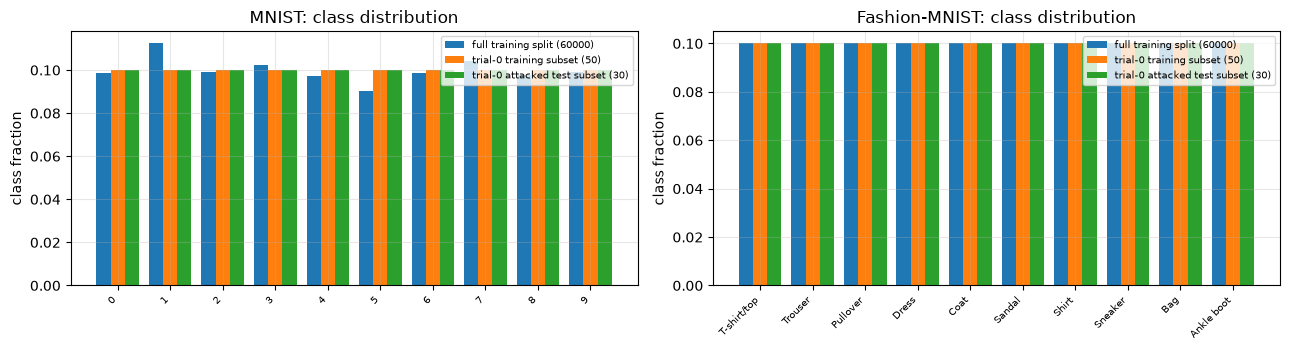

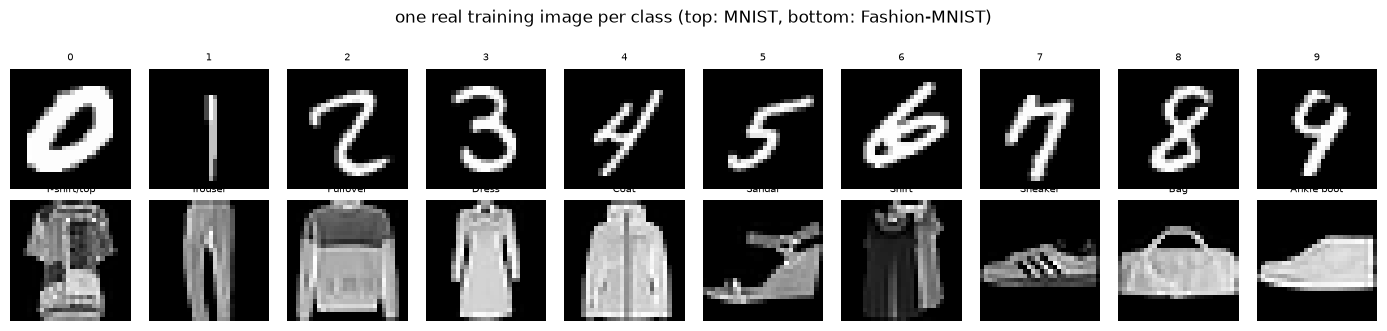

In [5]:
for ds in DATASETS:
    D = DATA[ds]; T0 = TRIAL[(ds, 0)]
    print("=" * 100)
    print(f"{FULL_NAME[ds]}: image array shape {T0['Xtr'].shape[1:]} = {T0['Xtr'].shape[1] * T0['Xtr'].shape[2]} features (pixel grey values, scaled to [0, 1]); "
          f"full data {D['shape_full'][0]} (train) and {D['shape_full'][1]} (test); trial-0 pixels min {T0['Xtr'].min():.2f}, max {T0['Xtr'].max():.2f}, mean {T0['Xtr'].mean():.3f}")
    print("feature names: pixel_r_c for row r, column c (r, c = 0..27), e.g. pixel_0_0 ... pixel_27_27")
    print("original label values:", sorted(set(D['ypool'].tolist())), "->", CLASS_NAMES[ds])
    cnt = pd.DataFrame({"class": CLASS_NAMES[ds], "full train (60000)": D["full_train_counts"], "full test (10000)": D["full_test_counts"],
                        "visualisation pool (2000)": np.bincount(D["ypool"], minlength=10),
                        f"trial-0 training subset ({len(T0['ytr'])})": np.bincount(T0["ytr"], minlength=10), f"trial-0 attacked test subset ({len(T0['yte'])})": np.bincount(T0["yte"], minlength=10)})
    display(cnt)

fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
for ax, ds in zip(axes, DATASETS):
    D = DATA[ds]; T0 = TRIAL[(ds, 0)]; w = 0.27; xs = np.arange(10)
    ax.bar(xs - w, D["full_train_counts"] / D["full_train_counts"].sum(), w, label="full training split (60000)")
    ax.bar(xs, np.bincount(T0["ytr"], minlength=10) / len(T0["ytr"]), w, label=f"trial-0 training subset ({N_TRAIN})")
    ax.bar(xs + w, np.bincount(T0["yte"], minlength=10) / len(T0["yte"]), w, label=f"trial-0 attacked test subset ({N_TEST})")
    ax.set_xticks(xs); ax.set_xticklabels(CLASS_NAMES[ds], rotation=45, ha="right", fontsize=7); ax.set_ylabel("class fraction"); ax.set_title(f"{FULL_NAME[ds]}: class distribution"); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(2, 10, figsize=(14, 3.2))
for r_, ds in enumerate(DATASETS):
    D = DATA[ds]
    for c in range(10):
        i = np.flatnonzero(D["ypool"] == c)[0]
        axes[r_, c].imshow(D["Xpool"][i], cmap="gray", vmin=0, vmax=1); axes[r_, c].axis("off"); axes[r_, c].set_title(CLASS_NAMES[ds][c], fontsize=7)
plt.suptitle("one real training image per class (top: MNIST, bottom: Fashion-MNIST)", y=1.02); plt.tight_layout(); plt.show()

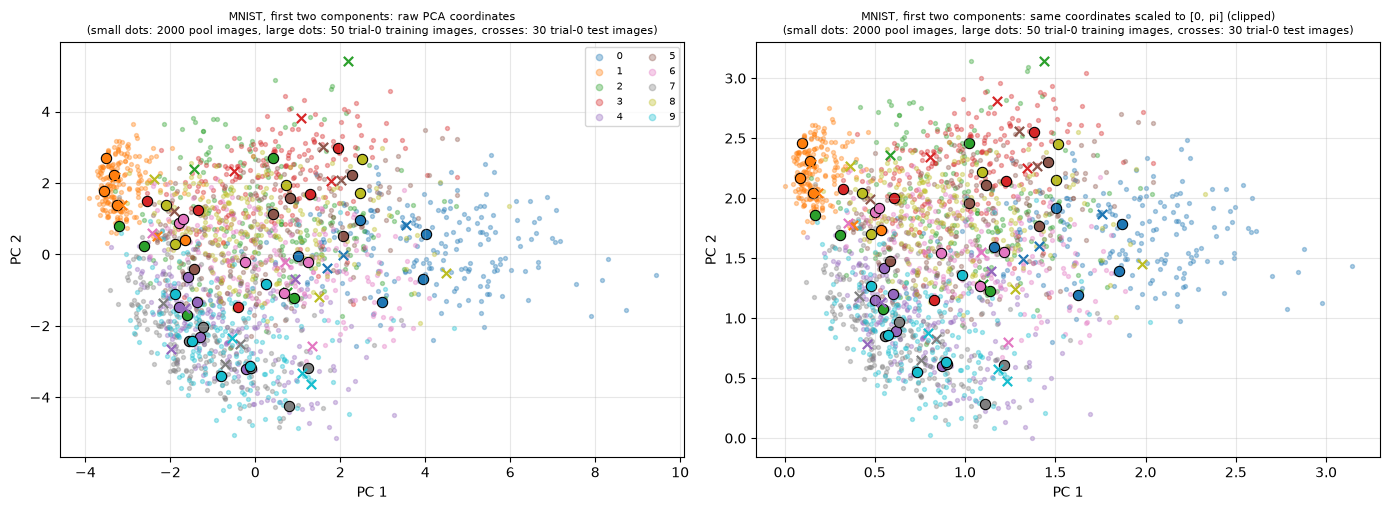

MNIST: variance explained by the two components = 16.5% (the 2-D view is a projection of 784 dimensions; classes overlap strongly in it)


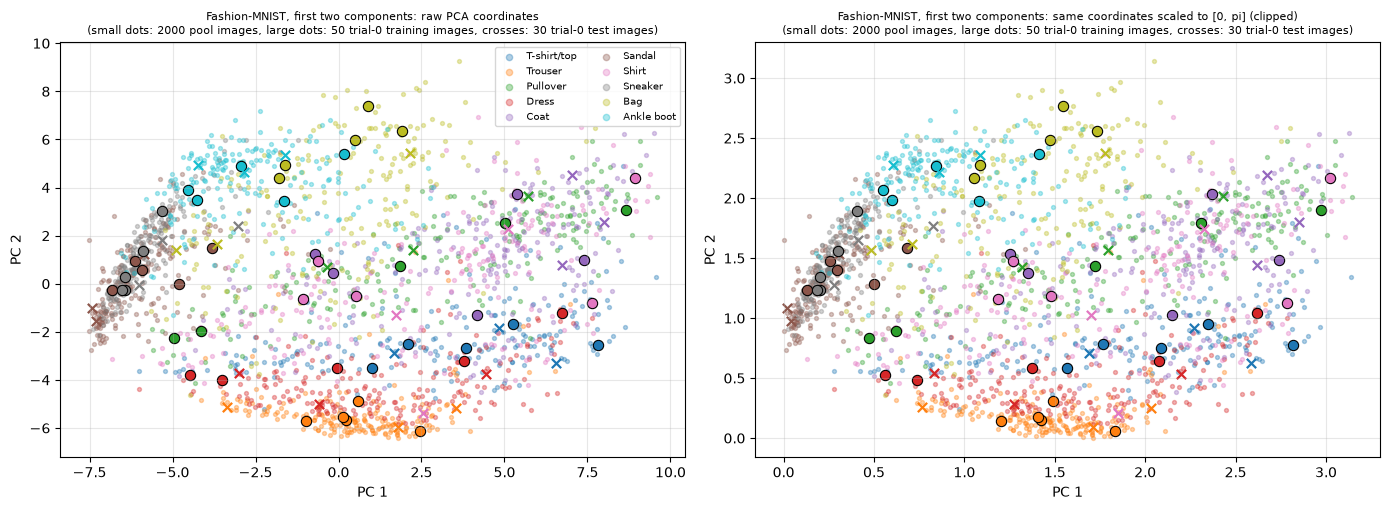

Fashion-MNIST: variance explained by the two components = 46.7% (the 2-D view is a projection of 784 dimensions; classes overlap strongly in it)


In [6]:
# 2-D scatter of real observations coloured by ground-truth label. PCA is fitted on the 2000-image training pool only; trial-0 train / test images are projected.
cmap = plt.get_cmap("tab10")
for ds in DATASETS:
    D = DATA[ds]; T0 = TRIAL[(ds, 0)]
    flat = lambda A: A.reshape(len(A), -1)
    pca = PCA(n_components=2, random_state=SEED).fit(flat(D["Xpool"]))
    Zp, Ztr, Zte = pca.transform(flat(D["Xpool"])), pca.transform(flat(T0["Xtr"])), pca.transform(flat(T0["Xte"]))
    sc = MinMaxScaler((0, np.pi)).fit(Zp)                                  # fitted on the training pool only
    fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
    for ax, (A, B, C, ttl) in zip(axes, [(Zp, Ztr, Zte, "raw PCA coordinates"),
                                         (sc.transform(Zp), np.clip(sc.transform(Ztr), 0, np.pi), np.clip(sc.transform(Zte), 0, np.pi), "same coordinates scaled to [0, pi] (clipped)")]):
        for c in range(10):
            m = D["ypool"] == c; ax.scatter(A[m, 0], A[m, 1], s=8, color=cmap(c), alpha=0.35, label=CLASS_NAMES[ds][c])
        for c in range(10):
            m = T0["ytr"] == c; ax.scatter(B[m, 0], B[m, 1], s=55, color=cmap(c), edgecolor="k", linewidth=0.8)
            m = T0["yte"] == c; ax.scatter(C[m, 0], C[m, 1], s=45, marker="x", color=cmap(c), linewidth=1.6)
        ax.set_xlabel("PC 1"); ax.set_ylabel("PC 2"); ax.set_title(f"{FULL_NAME[ds]}, first two components: {ttl}\n(small dots: 2000 pool images, large dots: 50 trial-0 training images, crosses: 30 trial-0 test images)", fontsize=8)
    axes[0].legend(fontsize=7, ncol=2, markerscale=1.6)
    plt.tight_layout(); plt.show()
    print(f"{FULL_NAME[ds]}: variance explained by the two components = {pca.explained_variance_ratio_.sum():.1%} (the 2-D view is a projection of 784 dimensions; classes overlap strongly in it)")

## 2. The five Ansatz architectures and an exact simulator

Each Ansatz is written as a short list of blocks on 4 qubits (`rot` = `Rot(phi, theta, omega)` with three free angles, `rx`/`ry`/`rz` with one free angle, `zz` = `CNOT - RZ(theta) - CNOT` with one free angle, `cx`):

| key | paper | blocks | free angles |
|---|---|---|---|
| `no_ent` | Fig. 3a, no entanglement | 4 x `Rot` | 12 |
| `zz_full` | Fig. 3b, ZZ full entanglement | 4 x `Rot`, ZZ on all 6 pairs | 18 |
| `zz_linear` | Fig. 3c, ZZ linear entanglement | 4 x `Rot`, ZZ on (0,1), (1,2), (2,3) | 15 |
| `zz_star` | Fig. 3d, ZZ star entanglement (centre = first qubit) | 4 x `Rot`, ZZ on (0,1), (0,2), (0,3) | 15 |
| `random` | Fig. 3e, random circuit | 4 random rotations + 2 random `CNOT`s (`# CHOICE`), new circuit per trial | 4 |

Two representations of the *same* block list are used: a small batched **NumPy statevector simulator** (`run_ops`), fast enough for 196 patches x many images with analytic gradients, and a **PennyLane QNode**
(built in the circuit section further below from the same list) that is drawn and used to cross-check the simulator with an assertion.
`Rot(phi, theta, omega)` follows PennyLane's convention `RZ(omega) RY(theta) RZ(phi)`; since the angles are random, this is the same family of unitaries as the paper's `Rz(a) Ry(b) Rz(c)`.

In [7]:
# ------------------------------------------------------------ Ansatz architectures (paper Fig. 3), 4 qubits ------------------------------------------------------------
# Blocks: ("rot", q) 3 angles | ("rx"|"ry"|"rz", q) 1 angle | ("zz", a, b) = CNOT(a,b) RZ(theta on b) CNOT(a,b), 1 angle | ("cx", c, t)
def arch_ops(name, rng=None):
    rots = [("rot", q) for q in range(4)]
    if name == "no_ent":    return rots
    if name == "zz_full":   return rots + [("zz", a, b) for a in range(4) for b in range(a + 1, 4)]
    if name == "zz_linear": return rots + [("zz", q, q + 1) for q in range(3)]
    if name == "zz_star":   return rots + [("zz", 0, q) for q in range(1, 4)]
    if name == "random":
        # CHOICE: Fig. 3e shows four rotation gates (Ry, Rx, Rz, Rx); we draw 4 rotations of random type on random qubits and insert 2 random CNOTs at random positions
        ops = [(str(rng.choice(["rx", "ry", "rz"])), int(rng.integers(4))) for _ in range(4)]
        for _ in range(2):
            c, t = rng.choice(4, 2, replace=False); ops.insert(int(rng.integers(len(ops) + 1)), ("cx", int(c), int(t)))
        return ops
    raise ValueError(name)

N_ANGLES = {"rot": 3, "rx": 1, "ry": 1, "rz": 1, "zz": 1, "cx": 0}
def n_params(ops): return sum(N_ANGLES[o[0]] for o in ops)

# ------------------------------------------------------------ batched NumPy statevector simulator ------------------------------------------------------------
# State array (B,2,2,2,2): axis q+1 is qubit q, qubit 0 is the most significant bit of the 16-vector (same convention as PennyLane).
def _rot(g, th):
    c, s = np.cos(th / 2), np.sin(th / 2)
    M = np.zeros((th.shape[0], 2, 2), complex)
    if g == "rx":
        M[:, 0, 0] = c; M[:, 1, 1] = c; M[:, 0, 1] = -1j * s; M[:, 1, 0] = -1j * s
    elif g == "ry":
        M[:, 0, 0] = c; M[:, 1, 1] = c; M[:, 0, 1] = -s; M[:, 1, 0] = s
    else:                                                    # rz
        M[:, 0, 0] = np.exp(-1j * th / 2); M[:, 1, 1] = np.exp(1j * th / 2)
    return M
_X = np.array([[0, 1], [1, 0]], complex)

def _apply1(psi, M, q):
    psi = np.moveaxis(psi, q + 1, 1)
    out = np.moveaxis(np.tensordot(M, psi, axes=([1], [1])), 0, 1) if M.ndim == 2 else np.einsum("bij,bj...->bi...", M, psi)
    return np.moveaxis(out, 1, q + 1)

def _cnot(psi, c, t):
    psi = psi.copy(); sl = [slice(None)] * 5; sl[c + 1] = 1
    sub = psi[tuple(sl)]; tq = t if t < c else t - 1
    sub = np.moveaxis(sub, tq + 1, 1)
    o = np.moveaxis(np.tensordot(_X, sub, axes=([1], [1])), 0, 1)
    psi[tuple(sl)] = np.moveaxis(o, 1, tq + 1)
    return psi

def run_ops(ops, theta, psi0):
    # theta: (B, n_params), psi0: (B,2,2,2,2)
    psi = psi0.astype(complex); p = 0
    for op in ops:
        g = op[0]
        if g == "rot":                                                         # qml.Rot(phi, theta, omega) = RZ(omega) RY(theta) RZ(phi)
            for gg in ("rz", "ry", "rz"): psi = _apply1(psi, _rot(gg, theta[:, p]), op[1]); p += 1
        elif g in ("rx", "ry", "rz"): psi = _apply1(psi, _rot(g, theta[:, p]), op[1]); p += 1
        elif g == "zz": psi = _cnot(psi, op[1], op[2]); psi = _apply1(psi, _rot("rz", theta[:, p]), op[2]); p += 1; psi = _cnot(psi, op[1], op[2])
        elif g == "cx": psi = _cnot(psi, op[1], op[2])
    return psi

def ansatz_unitary(ops, theta):
    # 16 x 16 unitary of the Ansatz for ONE parameter vector (columns = images of the basis states)
    psi0 = np.zeros((16, 2, 2, 2, 2), complex); psi0.reshape(16, 16)[np.arange(16), np.arange(16)] = 1
    return run_ops(ops, np.tile(theta[None, :], (16, 1)), psi0).reshape(16, 16).T

print("architecture | free angles | blocks")
for a in ARCHS:
    o = arch_ops(a, np.random.default_rng(SEED)); print(f"{a:>10} | {n_params(o):>11} | {o}")

architecture | free angles | blocks
    no_ent |          12 | [('rot', 0), ('rot', 1), ('rot', 2), ('rot', 3)]
   zz_full |          18 | [('rot', 0), ('rot', 1), ('rot', 2), ('rot', 3), ('zz', 0, 1), ('zz', 0, 2), ('zz', 0, 3), ('zz', 1, 2), ('zz', 1, 3), ('zz', 2, 3)]
 zz_linear |          15 | [('rot', 0), ('rot', 1), ('rot', 2), ('rot', 3), ('zz', 0, 1), ('zz', 1, 2), ('zz', 2, 3)]
   zz_star |          15 | [('rot', 0), ('rot', 1), ('rot', 2), ('rot', 3), ('zz', 0, 1), ('zz', 0, 2), ('zz', 0, 3)]
    random |           4 | [('rx', 3), ('ry', 1), ('ry', 3), ('rx', 2), ('cx', 2, 3), ('cx', 0, 3)]


## 3. The quanvolution layer, the classical twins, the dense heads and the attacks

**Quanvolution.** For a patch `x = (x0, x1, x2, x3)` (the four pixels of a 2 x 2 block) qubit *q* starts in `RY(pi x_q)|0> = cos(pi x_q / 2)|0> + sin(pi x_q / 2)|1>`, the Ansatz `U(theta)` is applied, and channel *k*
is `<Z_k>`. Because the encoding is a product state and `U` is a fixed 16 x 16 unitary, the layer is a fixed smooth map `[0,1]^4 -> [-1, 1]^4`, and its Jacobian can be written down exactly,
`d<Z_k>/dx_j = 2 pi Re(<phi| Z_k U |dpsi/dtheta_j>)`. The gradient needed by FGSM / PGD / MIM is therefore the **exact analytic gradient** (no sampling, no finite differences); it is verified against central finite differences below.

**Classical models.** CNN: `Conv2D(4 filters, 2 x 2, stride 2, relu)` (trainable, Keras Glorot init) followed by the head; DNN: `Flatten` followed by the same head on the raw pixels.

**Heads.** MNIST: `Flatten (784) -> Dense(10, softmax)`; Fashion-MNIST: `Dropout(0.3) -> Dense(32, relu) -> Dropout(0.3) -> Dense(64, relu) -> Dense(10, softmax)`. Trained with Adam (learning rate 0.001, batch 4, 30 epochs, sparse categorical cross-entropy),
written in NumPy so no TensorFlow is needed.

**Attacks (L-infinity, white-box, pixels clipped to [0, 1]).** FGSM `x' = clip(x + eps sign(grad))` (Algorithm 1), PGD `x_{t+1} = clip(Proj_eps(x_t + alpha sign(grad)))` (Algorithm 2),
MIM `g_{t+1} = mu g_t + grad / |grad|_1`, `x_{t+1} = clip(Proj_eps(x_t + alpha sign(g_{t+1})))` (Algorithm 3). The attacker sees the whole model, including the quantum layer.

In [8]:
# ------------------------------------------------------------ data layout: 2x2 patches, stride 2 ------------------------------------------------------------
def to_patches(X):          # (N,28,28) -> (N,196,4); pixel order (0,0),(0,1),(1,0),(1,1) = qubits 0..3
    n = X.shape[0]; return X.reshape(n, 14, 2, 14, 2).transpose(0, 1, 3, 2, 4).reshape(n, 196, 4)
def from_patches(P):
    n = P.shape[0]; return P.reshape(n, 14, 14, 2, 2).transpose(0, 1, 3, 2, 4).reshape(n, 28, 28)

IDX = np.arange(16)
ZMAT = np.stack([1.0 - 2.0 * ((IDX >> (3 - k)) & 1) for k in range(4)], 1)       # (16,4): diagonal of Z_k for the 16 basis states

def _kron4(v0, v1, v2, v3):
    n = v0.shape[0]
    a = (v0[:, :, None] * v1[:, None, :]).reshape(n, 4); b = (v2[:, :, None] * v3[:, None, :]).reshape(n, 4)
    return (a[:, :, None] * b[:, None, :]).reshape(n, 16)

def product_state(P, deriv=None):
    # RY(pi x_q)|0> on every qubit (qubit 0 = most significant); deriv=j returns d/d(angle_j) of it. P holds the ANGLES (pi * pixel)
    c, s = np.cos(P / 2), np.sin(P / 2)
    v = [np.stack([c[:, q], s[:, q]], 1) for q in range(4)]
    if deriv is not None: v[deriv] = 0.5 * np.stack([-s[:, deriv], c[:, deriv]], 1)
    return _kron4(*v)

class Quanv:
    """Frozen quanvolution layer: <Z_k> of U(theta) RY(pi x)|0000>, 2x2 patches, stride 2, 4 channels -> 784 features."""
    trainable = False
    def __init__(self, ops, theta):
        self.ops, self.theta = ops, theta
        self.U = ansatz_unitary(ops, theta)
        self.RI = np.concatenate([self.U.T.real, self.U.T.imag], 1)          # psi @ RI = [Re, Im] of U psi
    def _amp(self, P):
        A = product_state(np.pi * P) @ self.RI; return A[:, :16], A[:, 16:]
    def forward(self, X, train=False):                                       # processed in chunks of 50 images to keep memory small
        return np.concatenate([self._forward(X[i:i + 50]) for i in range(0, len(X), 50)])
    def backward(self, X, g):                                                # g: (N,784) upstream gradient -> gradient w.r.t. the images
        return np.concatenate([self._backward(X[i:i + 50], g[i:i + 50]) for i in range(0, len(X), 50)])
    def _forward(self, X):
        Ar, Ai = self._amp(to_patches(X).reshape(-1, 4))
        return ((Ar ** 2 + Ai ** 2) @ ZMAT).reshape(X.shape[0], 196 * 4)
    def _backward(self, X, g):
        P = to_patches(X).reshape(-1, 4); g = g.reshape(-1, 4)
        Ar, Ai = self._amp(P); w = g @ ZMAT.T; out = np.empty_like(P)
        for j in range(4):
            dA = product_state(np.pi * P, j) @ self.RI
            out[:, j] = 2 * np.pi * np.sum(w * (Ar * dA[:, :16] + Ai * dA[:, 16:]), 1)
        return from_patches(out.reshape(X.shape[0], 196, 4))

def glorot(rng, fan_in, fan_out):
    lim = math.sqrt(6.0 / (fan_in + fan_out)); return rng.uniform(-lim, lim, (fan_in, fan_out))

class ConvFront:
    """Classical Conv2D(4 filters, 2x2, stride 2, relu), trainable, Keras Glorot-uniform kernel (fan_in 4, fan_out 16), zero bias."""
    trainable = True
    def __init__(self, rng):
        lim = math.sqrt(6.0 / (4 + 16)); self.W = rng.uniform(-lim, lim, (4, 4)); self.b = np.zeros(4)
    def params(self): return [self.W, self.b]
    def grads(self): return [self.gW, self.gb]
    def forward(self, X, train=False):
        self.P = to_patches(X); self.z = self.P @ self.W + self.b; return np.maximum(self.z, 0).reshape(X.shape[0], 784)
    def backward(self, X, g):                                                # uses the cache of the last forward call on the same X
        gz = g.reshape(-1, 196, 4) * (self.z > 0)
        self.gW = np.einsum("npi,npj->ij", self.P, gz); self.gb = gz.sum((0, 1))
        return from_patches(gz @ self.W.T)

class FlatFront:
    """DNN: no convolution, the head sees the 784 raw pixels."""
    trainable = False
    def forward(self, X, train=False): return X.reshape(X.shape[0], 784)
    def backward(self, X, g): return g.reshape(-1, 28, 28)

class Dense:
    def __init__(self, rng, n_in, n_out, relu):
        self.W, self.b, self.relu = glorot(rng, n_in, n_out), np.zeros(n_out), relu
    def params(self): return [self.W, self.b]
    def grads(self): return [self.gW, self.gb]
    def forward(self, x, train=False):
        self.x = x; self.z = x @ self.W + self.b; return np.maximum(self.z, 0) if self.relu else self.z
    def backward(self, g):
        if self.relu: g = g * (self.z > 0)
        self.gW = self.x.T @ g; self.gb = g.sum(0); return g @ self.W.T

class Drop:
    def __init__(self, rate, rng): self.rate, self.rng, self.m = rate, rng, None
    def params(self): return []
    def grads(self): return []
    def forward(self, x, train=False):
        if not train: self.m = None; return x
        self.m = (self.rng.random(x.shape) >= self.rate) / (1.0 - self.rate); return x * self.m          # inverted dropout as in Keras
    def backward(self, g): return g if self.m is None else g * self.m

def build_head(ds, rng_init, rng_drop):
    if ds == "MNIST": return [Dense(rng_init, 784, 10, False)]                                   # direct path to the softmax (yellow box of Fig. 4)
    return [Drop(DROPOUT, rng_drop), Dense(rng_init, 784, 32, True), Drop(DROPOUT, rng_drop), Dense(rng_init, 32, 64, True), Dense(rng_init, 64, 10, False)]   # red box of Fig. 4

def softmax(z):
    z = z - z.max(1, keepdims=True); e = np.exp(z); return e / e.sum(1, keepdims=True)

class Model:
    def __init__(self, front, head): self.front, self.head = front, head
    def logits(self, X, train=False):
        h = self.front.forward(X, train)
        for L in self.head: h = L.forward(h, train)
        return h
    def pred(self, X): return self.logits(X).argmax(1)
    def acc(self, X, y): return float((self.pred(X) == y).mean())
    def grad(self, X, y):                                                    # gradient of the per-sample cross-entropy w.r.t. the input image (inference mode)
        p = softmax(self.logits(X)); p[np.arange(len(y)), y] -= 1
        for L in reversed(self.head): p = L.backward(p)
        return self.front.backward(X, p)

def train_model(model, X, y, rng, epochs=EPOCHS, bs=BATCH_SIZE, lr=LR):
    # Adam with Keras defaults (beta1 0.9, beta2 0.999, eps 1e-7), batch size 4, sparse categorical cross-entropy (mean over the batch)
    params = [p for L in model.head for p in L.params()] + (model.front.params() if model.front.trainable else [])
    m_ = [np.zeros_like(p) for p in params]; v_ = [np.zeros_like(p) for p in params]; b1, b2, eps = 0.9, 0.999, 1e-7; t = 0
    Y = np.eye(10)[y]; n = len(y)
    F_all = None if model.front.trainable else model.front.forward(X)          # frozen front end (quantum layer / flatten): features computed once
    for ep in range(epochs):
        perm = rng.permutation(n)
        for i in range(0, n, bs):
            idx = perm[i:i + bs]
            h = model.front.forward(X[idx], True) if model.front.trainable else F_all[idx]
            for L in model.head: h = L.forward(h, True)
            g = (softmax(h) - Y[idx]) / len(idx)
            for L in reversed(model.head): g = L.backward(g)
            if model.front.trainable: model.front.backward(X[idx], g)
            grads = [q for L in model.head for q in L.grads()] + (model.front.grads() if model.front.trainable else [])
            t += 1; a = lr * math.sqrt(1 - b2 ** t) / (1 - b1 ** t)
            for p, gr, mm, vv in zip(params, grads, m_, v_):
                mm *= b1; mm += (1 - b1) * gr; vv *= b2; vv += (1 - b2) * gr ** 2; p -= a * mm / (np.sqrt(vv) + eps)
    return model

# ---------------------------------------------------- the three white-box attacks (paper Algorithms 1-3) ----------------------------------------------------
def fgsm(m, X, y, eps): return np.clip(X + eps * np.sign(m.grad(X, y)), 0, 1)
def pgd(m, X, y, eps, k):
    alpha = 2.5 * eps / k; xa = X.copy()                                     # CHOICE: step 2.5 eps / k, no random start
    for _ in range(k):
        xa = np.clip(np.clip(xa + alpha * np.sign(m.grad(xa, y)), X - eps, X + eps), 0, 1)
    return xa
def mim(m, X, y, eps, k, mu=MIM_MU):
    alpha = 2.5 * eps / k; xa = X.copy(); gm = np.zeros_like(X)
    for _ in range(k):
        gr = m.grad(xa, y); gm = mu * gm + gr / (np.abs(gr).sum((1, 2), keepdims=True) + 1e-12)       # per-image L1 normalisation
        xa = np.clip(np.clip(xa + alpha * np.sign(gm), X - eps, X + eps), 0, 1)
    return xa

# --- sanity check: analytic input gradient of the whole QuNN vs central finite differences ---
_r = np.random.default_rng(SEED)
_Xs, _ys = TRIAL[("MNIST", 0)]["Xtr"][:3], TRIAL[("MNIST", 0)]["ytr"][:3]
for _a in ("zz_full", "random"):
    _ops = arch_ops(_a, _r); _q = Quanv(_ops, _r.uniform(0, 2 * np.pi, n_params(_ops)))
    _m = train_model(Model(_q, build_head("MNIST", _r, _r)), TRIAL[("MNIST", 0)]["Xtr"], TRIAL[("MNIST", 0)]["ytr"], _r, epochs=2)
    _g = _m.grad(_Xs, _ys); _loss = lambda X: float(-np.log(softmax(_m.logits(X))[np.arange(3), _ys]).sum())
    errs = []
    for (_i, _j) in [(13, 13), (14, 12), (12, 15), (9, 14)]:
        e = np.zeros_like(_Xs); e[1, _i, _j] = 1e-6
        errs.append(abs((_loss(_Xs + e) - _loss(_Xs - e)) / 2e-6 - _g[1, _i, _j]))
    print(f"{_a}: max |analytic - finite-difference| input gradient over 4 pixels = {max(errs):.2e}  (gradient scale ~ {np.abs(_g).max():.2e})")
    assert max(errs) < 1e-5

zz_full: max |analytic - finite-difference| input gradient over 4 pixels = 3.25e-10  (gradient scale ~ 2.98e-01)
random: max |analytic - finite-difference| input gradient over 4 pixels = 2.56e-10  (gradient scale ~ 2.52e-01)


## Quantum Circuit Architecture

Every QuNN in this notebook uses one of the circuits drawn below: a layer of `RY(pi x_q)` encoding gates (`qml.AngleEmbedding(pi x, rotation="Y")`, one per qubit, angle = pi times the pixel value), the Ansatz (parameterised rotations and, for the ZZ architectures,
`CNOT - RZ - CNOT` entanglers), and a Pauli-Z read-out of each qubit (four expectation values = four output channels). The circuit is executed once per 2 x 2 patch (196 times per image). The Ansatz angles are **frozen**
(drawn once per trial from [0, 2 pi) and never trained); the only trainable parameters of a QuNN are those of the classical head (7 850 for MNIST, 27 882 for Fashion-MNIST).

The cell after the next one **asserts** that the NumPy simulator used for all the experiments gives the same `<Z_k>` as the PennyLane QNode for these exact circuits (all five architectures, random angles, random patches).
Where the paper omits a detail (the random circuit; the angle distribution) the choice is documented in the table at the top and in `arch_ops`. For the random architecture the drawing shows the circuit of trial 0.

In [9]:
dev = qml.device("default.qubit", wires=4)

def make_qnode(ops):
    """PennyLane QNode of one quanvolution patch: angle encoding RY(pi x), Ansatz blocks, <Z> on each qubit."""
    @qml.qnode(dev)
    def circuit(x, theta):
        qml.AngleEmbedding(np.pi * x, wires=range(4), rotation="Y")
        p = 0
        for op in ops:
            g = op[0]
            if g == "rot": qml.Rot(theta[p], theta[p + 1], theta[p + 2], wires=op[1]); p += 3
            elif g == "rx": qml.RX(theta[p], wires=op[1]); p += 1
            elif g == "ry": qml.RY(theta[p], wires=op[1]); p += 1
            elif g == "rz": qml.RZ(theta[p], wires=op[1]); p += 1
            elif g == "zz": qml.CNOT(wires=[op[1], op[2]]); qml.RZ(theta[p], wires=op[2]); qml.CNOT(wires=[op[1], op[2]]); p += 1
            elif g == "cx": qml.CNOT(wires=[op[1], op[2]])
        return [qml.expval(qml.PauliZ(w)) for w in range(4)]
    return circuit

# the circuits actually trained in trial 0 (random architecture: the circuit of trial 0)
def trial_arch(arch, t):
    r = np.random.default_rng(np.random.SeedSequence([SEED, t, 31337, ARCHS.index(arch)]))
    ops = arch_ops(arch, r); return ops, r.uniform(0, 2 * np.pi, n_params(ops))          # CHOICE: random frozen Ansatz angles, uniform in [0, 2 pi)

# --- sanity check: NumPy simulator == PennyLane QNode, for every architecture (3 random-circuit draws), random angles, random patches ---
_r = np.random.default_rng(SEED + 7); worst = 0.0
for arch in ARCHS:
    for t in (range(3) if arch == "random" else [0]):
        ops, th = trial_arch(arch, t); th = _r.uniform(0, 2 * np.pi, n_params(ops)); q = Quanv(ops, th); qn = make_qnode(ops)
        P = _r.uniform(0, 1, (6, 4)); fq = q.forward(from_patches(np.tile(P[:, None, :], (1, 196, 1)))).reshape(6, 196, 4)[:, 0, :]
        for i in range(6):
            worst = max(worst, np.abs(np.array(qn(P[i], th)) - fq[i]).max())
print(f"max |<Z_k>_numpy - <Z_k>_pennylane| over the 5 architectures = {worst:.2e}")
assert worst < 1e-10, "NumPy simulator and PennyLane disagree"
print("OK: the NumPy simulator used below is the same function as the PennyLane circuits drawn below.")

max |<Z_k>_numpy - <Z_k>_pennylane| over the 5 architectures = 1.11e-15
OK: the NumPy simulator used below is the same function as the PennyLane circuits drawn below.


In [10]:
# circuit facts: qubits, depth, parameter counts, gate content (PennyLane specs of the executed QNode, decomposed into RX/RY/RZ/CNOT; the head sizes are the trainable parameters)
HEAD_PARAMS = {"MNIST": 784 * 10 + 10, "FMNIST": 784 * 32 + 32 + 32 * 64 + 64 + 64 * 10 + 10}
rows = []
for arch in ARCHS:
    ops, th = trial_arch(arch, 0); qn = make_qnode(ops); x0 = np.full(4, 0.5)
    sp = qml.specs(qml.transforms.decompose(qn, gate_set={"RX", "RY", "RZ", "CNOT"}), level="device")(x0, th)          # decomposed into RX/RY/RZ/CNOT (Rot -> RZ RY RZ)
    rows.append({"architecture": arch, "qubits": sp.num_device_wires, "depth (encoding + Ansatz)": sp.resources.depth, "frozen Ansatz angles": n_params(ops),
                 "encoding angles (pixels)": 4, "gates": ", ".join(f"{k}:{v}" for k, v in sorted(sp.resources.gate_types.items())), "measurements": "4 x <Z>"})
circ_table = pd.DataFrame(rows).set_index("architecture"); display(circ_table)
print("Trainable parameters of one QuNN = classical head only (the quantum circuit is a frozen feature extractor, as in the paper):", HEAD_PARAMS,
      "| circuits executed per image:", 196, "(14 x 14 patches), 4 qubits each")

,qubits,depth (encoding + Ansatz),frozen Ansatz angles,encoding angles (pixels),gates,measurements
architecture,,,,,,
no_ent,4,4,12,4,"RY:8, RZ:8",4 x <Z>
zz_full,4,19,18,4,"CNOT:12, RY:8, RZ:14",4 x <Z>
zz_linear,4,13,15,4,"CNOT:6, RY:8, RZ:11",4 x <Z>
zz_star,4,13,15,4,"CNOT:6, RY:8, RZ:11",4 x <Z>
random,4,4,4,4,"CNOT:2, RX:1, RY:5, RZ:2",4 x <Z>


Trainable parameters of one QuNN = classical head only (the quantum circuit is a frozen feature extractor, as in the paper): {'MNIST': 7850, 'FMNIST': 27882} | circuits executed per image: 196 (14 x 14 patches), 4 qubits each


Matplotlib is building the font cache; this may take a moment.


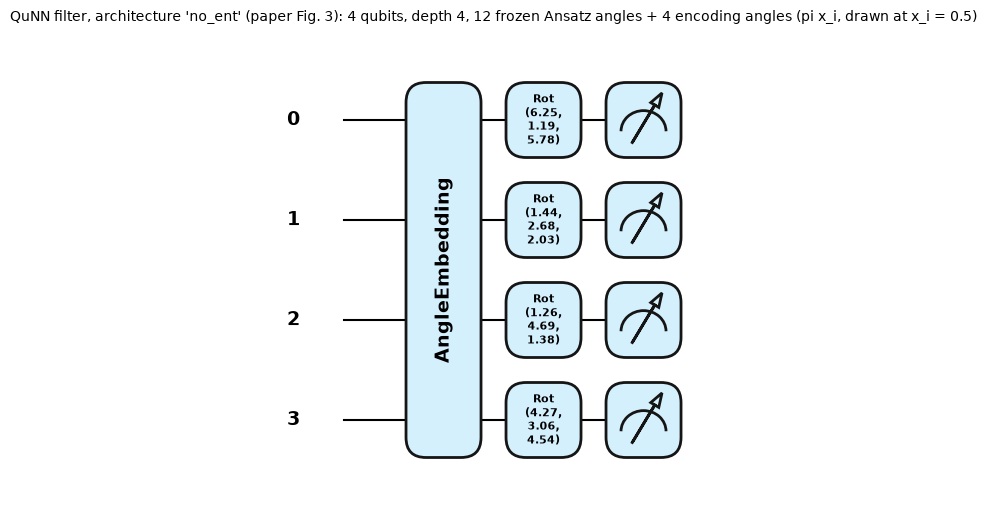

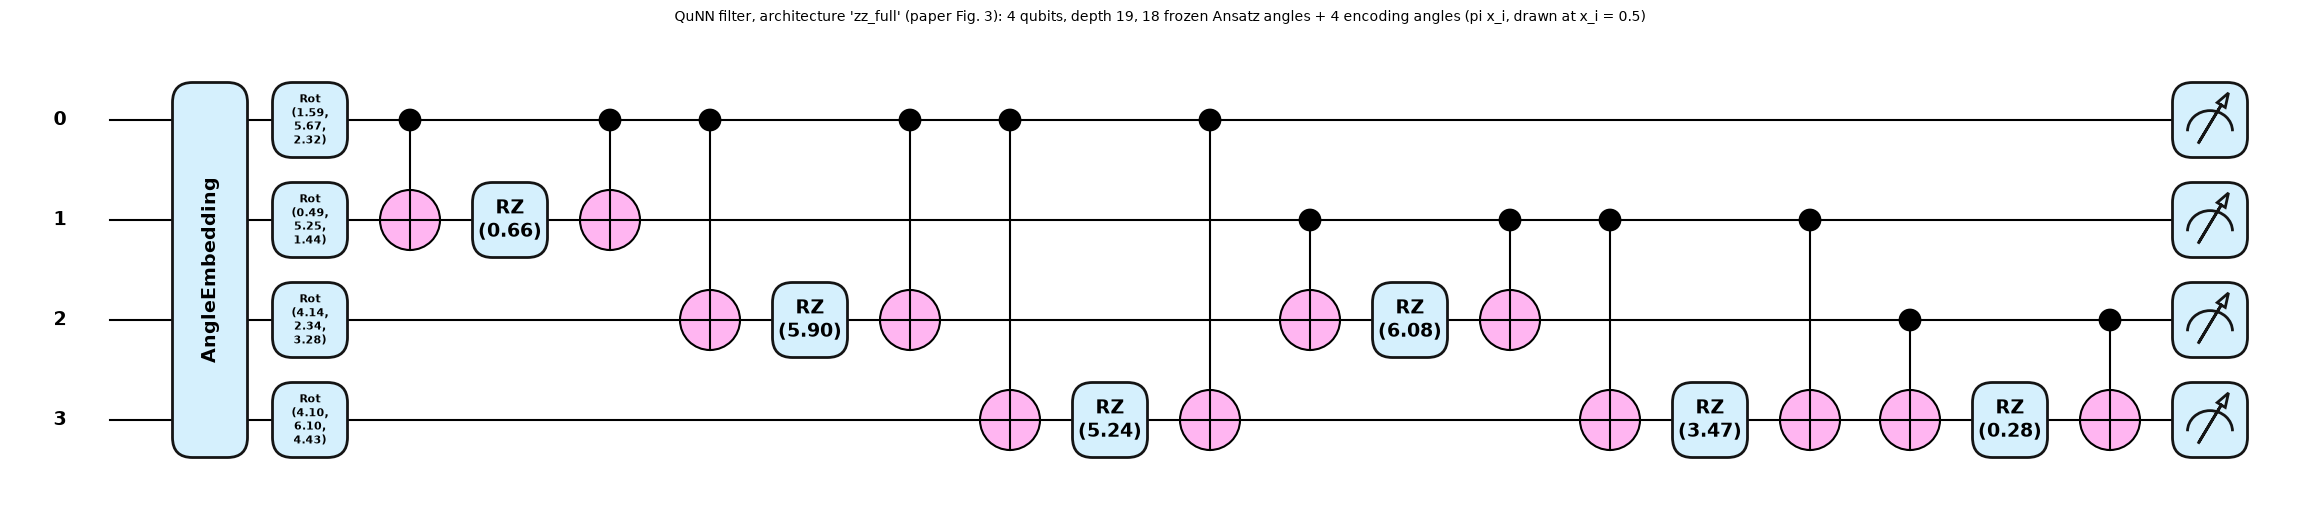

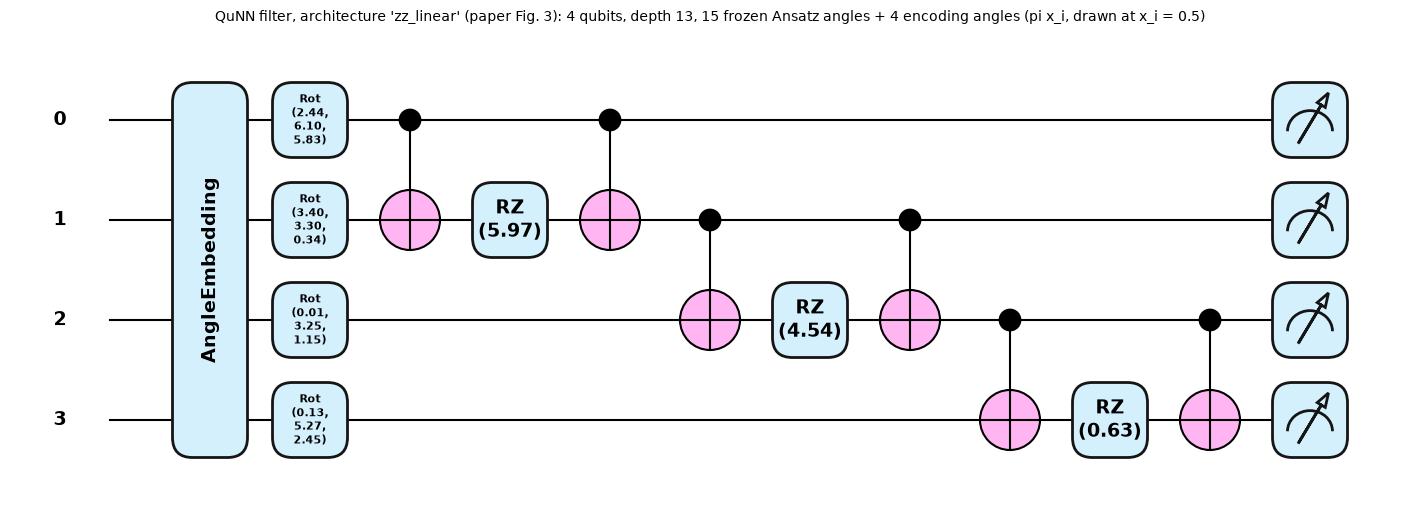

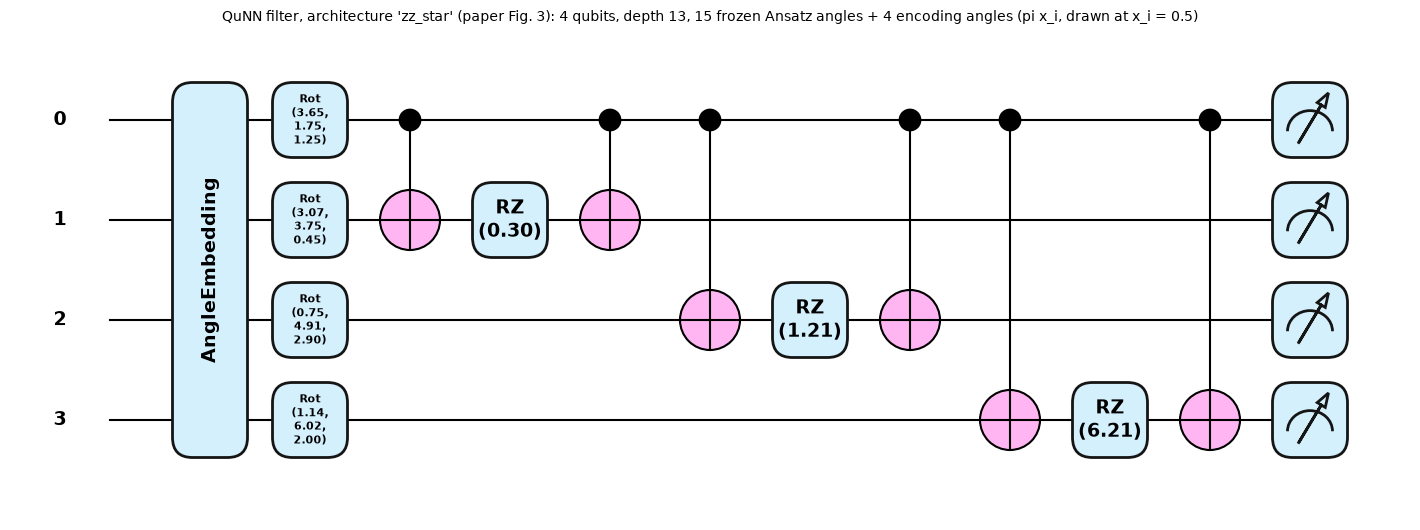

Matplotlib is building the font cache; this may take a moment.


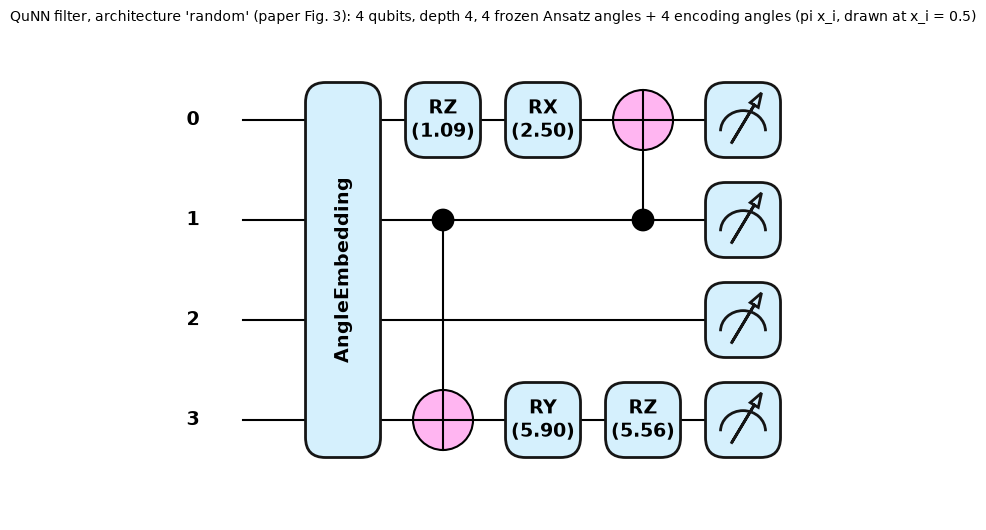

In [11]:
# draw every distinct architecture that is trained or evaluated (the QNode that is actually executed: encoding, Ansatz, read-out)
for arch in ARCHS:
    ops, th = trial_arch(arch, 0); qn = make_qnode(ops)
    fig, ax = qml.draw_mpl(qn, decimals=2, style="pennylane")(np.full(4, 0.5), th)
    fig.suptitle(f"QuNN filter, architecture '{arch}' (paper Fig. 3): 4 qubits, depth {circ_table.loc[arch, 'depth (encoding + Ansatz)']}, {n_params(ops)} frozen Ansatz angles + 4 encoding angles (pi x_i, drawn at x_i = 0.5)", fontsize=10, y=1.02)
    display(fig); plt.close(fig)

## 4. Quantum feature space of real data

What does the frozen quantum filter do to real images? For each architecture the 784 quanvolution features of 1000 real training-pool images are projected with PCA (fitted on these training images) and coloured by their ground-truth label.
The 784-dimensional feature map is what the dense head sees.

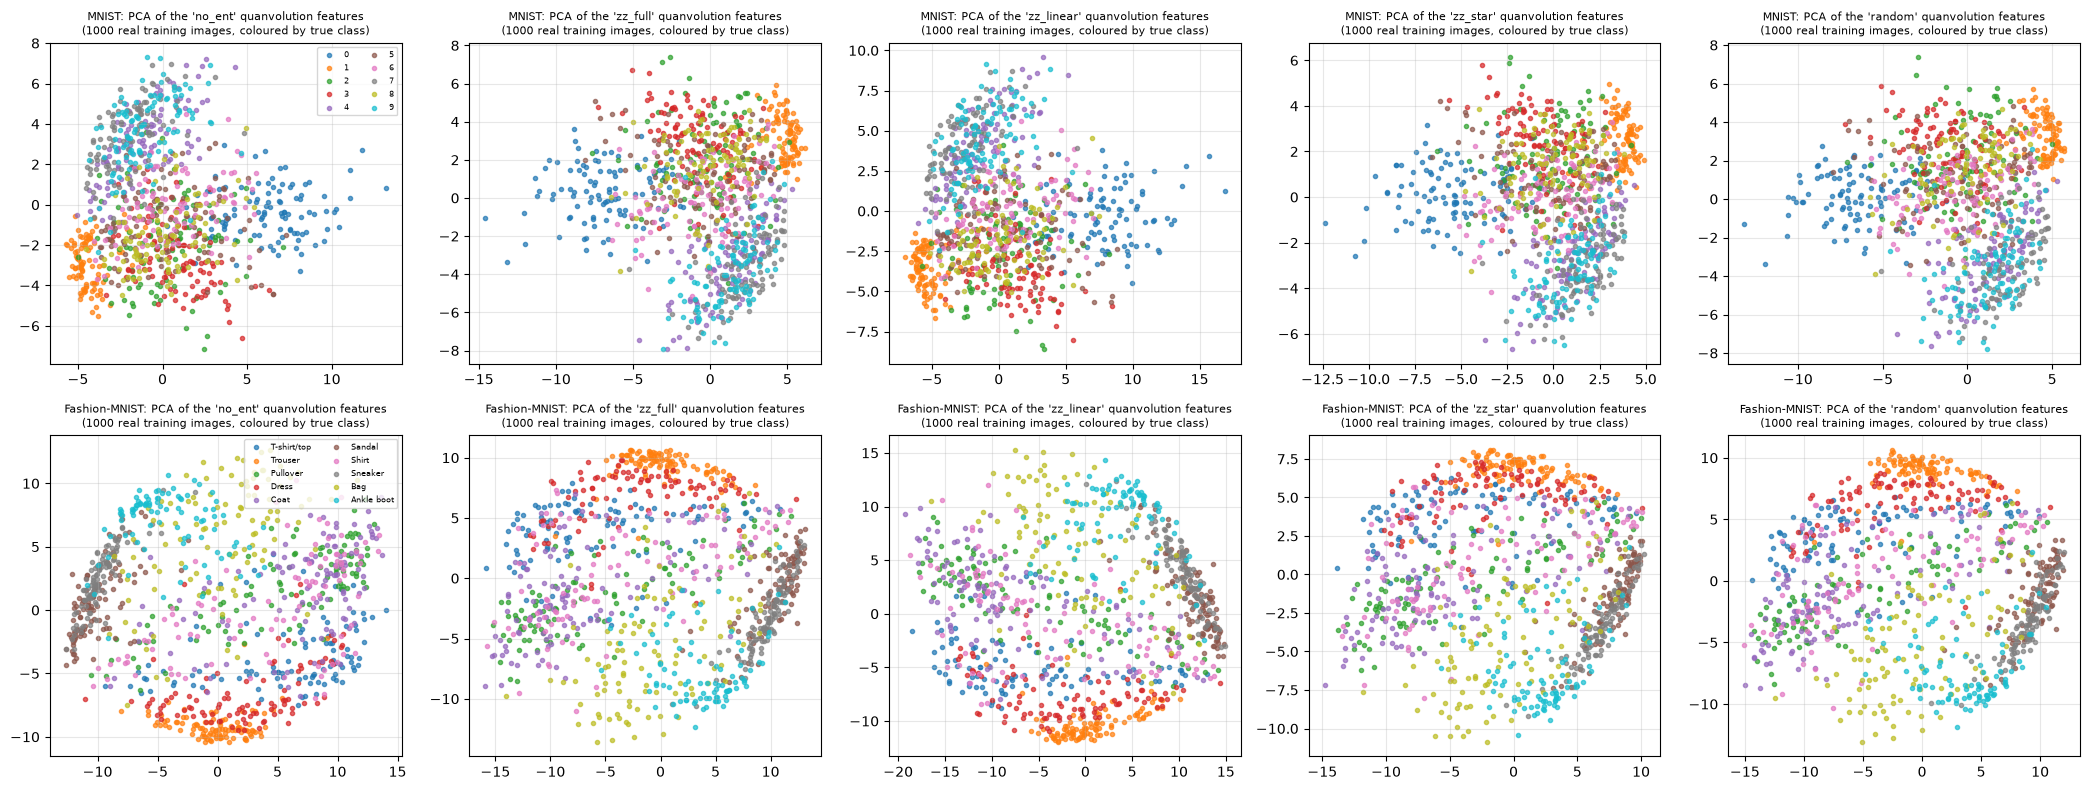

In [12]:
cmap = plt.get_cmap("tab10")
fig, axes = plt.subplots(2, 5, figsize=(21, 8))
for r_, ds in enumerate(DATASETS):
    D = DATA[ds]; Xp, yp = D["Xpool"][::2], D["ypool"][::2]
    for c_, arch in enumerate(ARCHS):
        ops, th = trial_arch(arch, 0); F = Quanv(ops, th).forward(Xp); Z = PCA(n_components=2, random_state=SEED).fit_transform(F)
        for c in range(10):
            mk = yp == c; axes[r_, c_].scatter(Z[mk, 0], Z[mk, 1], s=9, color=cmap(c), alpha=0.7, label=CLASS_NAMES[ds][c])
        axes[r_, c_].set_title(f"{FULL_NAME[ds]}: PCA of the '{arch}' quanvolution features\n(1000 real training images, coloured by true class)", fontsize=8)
axes[0, 0].legend(fontsize=6, ncol=2); axes[1, 0].legend(fontsize=6, ncol=2); plt.tight_layout(); plt.show()

## 5. Train every model, attack it, repeat over trials

For every dataset and trial the loop below

1. draws the 50 training and 30 test images (shared by all models of the trial),
2. builds the two classical models (CNN, DNN) and the five QuNNs (frozen random quantum filter of each architecture), all with the same dense-head initialisation and the same shuffling and dropout streams,
3. trains each model with Adam (batch 4, 30 epochs, learning rate 0.001),
4. records the clean test accuracy and the test accuracy on FGSM, PGD and MIM adversarial examples for every epsilon of the grid (one gradient is enough for all FGSM epsilons).

A progress line is printed per dataset and trial.

In [13]:
MODELS = ["CNN", "DNN"] + ARCHS
RES = {}          # RES[(dataset, model)] = {"fgsm": [per trial], "pgd": [...], "mim": [...], "train_acc": [...], "clean": [...]}
T_START = time.time()

def make_model(model, ds, ds_i, t):
    r_front = np.random.default_rng(np.random.SeedSequence([SEED, t, ds_i, MODELS.index(model), 1]))
    r_init = np.random.default_rng(np.random.SeedSequence([SEED, t, ds_i, 12345]))          # same head initialisation for every model of a trial
    r_drop = np.random.default_rng(np.random.SeedSequence([SEED, t, ds_i, 54321]))
    if model == "CNN": front = ConvFront(r_front)
    elif model == "DNN": front = FlatFront()
    else: ops, th = trial_arch(model, t); front = Quanv(ops, th)
    return Model(front, build_head(ds, r_init, r_drop))

def run_one(model, ds, ds_i, t):
    D = TRIAL[(ds, t)]; m = make_model(model, ds, ds_i, t)
    train_model(m, D["Xtr"], D["ytr"], np.random.default_rng(np.random.SeedSequence([SEED, t, ds_i, 424242])))      # same shuffling stream for every model
    X, y = D["Xte"], D["yte"]; sg = np.sign(m.grad(X, y)); clean = m.acc(X, y)
    f_acc = [m.acc(np.clip(X + e * sg, 0, 1), y) if e > 0 else clean for e in FGSM_EPS]
    p_acc = [m.acc(pgd(m, X, y, e, ATTACK_ITERS), y) if e > 0 else clean for e in ITER_EPS]
    m_acc = [m.acc(mim(m, X, y, e, ATTACK_ITERS), y) if e > 0 else clean for e in ITER_EPS]
    return dict(fgsm=f_acc, pgd=p_acc, mim=m_acc, clean=clean, train_acc=m.acc(D["Xtr"], D["ytr"]))

for ds_i, ds in enumerate(DATASETS):
    for t in range(N_TRIALS):
        t_s = time.time(); recs = {model: run_one(model, ds, ds_i, t) for model in MODELS}
        for model in MODELS:
            R = RES.setdefault((ds, model), {"fgsm": [], "pgd": [], "mim": [], "clean": [], "train_acc": []})
            for key in R: R[key].append(recs[model][key])
        print(f"{FULL_NAME[ds]:>13} trial {t + 1}/{N_TRIALS} done in {time.time() - t_s:4.0f} s (elapsed {(time.time() - T_START) / 60:.1f} min)   clean test acc: " + ", ".join(f"{k} {recs[k]['clean']:.2f}" for k in MODELS))
for R in RES.values():
    for key in ("fgsm", "pgd", "mim"): R[key] = np.array(R[key])
print(f"total {(time.time() - T_START) / 60:.1f} min")

        MNIST trial 1/7 done in  124 s (elapsed 2.1 min)   clean test acc: CNN 0.53, DNN 0.60, no_ent 0.53, zz_full 0.53, zz_linear 0.53, zz_star 0.50, random 0.57


        MNIST trial 2/7 done in  115 s (elapsed 4.0 min)   clean test acc: CNN 0.73, DNN 0.73, no_ent 0.67, zz_full 0.73, zz_linear 0.67, zz_star 0.73, random 0.57


        MNIST trial 3/7 done in  154 s (elapsed 6.5 min)   clean test acc: CNN 0.63, DNN 0.63, no_ent 0.60, zz_full 0.50, zz_linear 0.50, zz_star 0.63, random 0.53


        MNIST trial 4/7 done in  142 s (elapsed 8.9 min)   clean test acc: CNN 0.73, DNN 0.73, no_ent 0.73, zz_full 0.63, zz_linear 0.63, zz_star 0.70, random 0.63


        MNIST trial 5/7 done in  133 s (elapsed 11.1 min)   clean test acc: CNN 0.57, DNN 0.63, no_ent 0.67, zz_full 0.60, zz_linear 0.60, zz_star 0.57, random 0.63


...

Fashion-MNIST trial 3/7 done in  132 s (elapsed 22.2 min)   clean test acc: CNN 0.60, DNN 0.57, no_ent 0.70, zz_full 0.47, zz_linear 0.57, zz_star 0.70, random 0.57


Fashion-MNIST trial 4/7 done in  119 s (elapsed 24.1 min)   clean test acc: CNN 0.67, DNN 0.60, no_ent 0.53, zz_full 0.57, zz_linear 0.63, zz_star 0.63, random 0.60


Fashion-MNIST trial 5/7 done in  124 s (elapsed 26.2 min)   clean test acc: CNN 0.70, DNN 0.73, no_ent 0.67, zz_full 0.63, zz_linear 0.63, zz_star 0.70, random 0.70


Fashion-MNIST trial 6/7 done in  176 s (elapsed 29.1 min)   clean test acc: CNN 0.70, DNN 0.73, no_ent 0.67, zz_full 0.67, zz_linear 0.67, zz_star 0.70, random 0.67


Fashion-MNIST trial 7/7 done in  109 s (elapsed 31.0 min)   clean test acc: CNN 0.53, DNN 0.60, no_ent 0.47, zz_full 0.53, zz_linear 0.50, zz_star 0.47, random 0.47
total 31.0 min


In [14]:
# clean accuracy (eps = 0) and training accuracy, mean +- std over trials
rows = []
for model in MODELS:
    row = {"model": {"CNN": "CNN (Conv2D)", "DNN": "DNN (dense only)"}.get(model, f"QuNN {model}")}
    for ds in DATASETS:
        R = RES[(ds, model)]
        row[f"{ds} train acc"] = f"{np.mean(R['train_acc']):.3f}"
        row[f"{ds} clean test acc"] = f"{np.mean(R['clean']):.3f} +- {np.std(R['clean']):.3f}"
    rows.append(row)
display(pd.DataFrame(rows).set_index("model"))

,MNIST train acc,MNIST clean test acc,FMNIST train acc,FMNIST clean test acc
model,,,,
CNN (Conv2D),1.000,0.648 +- 0.071,0.963,0.643 +- 0.056
DNN (dense only),1.000,0.671 +- 0.049,0.957,0.633 +- 0.067
QuNN no_ent,1.000,0.633 +- 0.059,0.997,0.629 +- 0.084
QuNN zz_full,1.000,0.614 +- 0.073,0.994,0.595 +- 0.070
QuNN zz_linear,1.000,0.595 +- 0.055,0.991,0.610 +- 0.056
QuNN zz_star,1.000,0.600 +- 0.084,1.000,0.643 +- 0.077
QuNN random,1.000,0.590 +- 0.039,1.000,0.595 +- 0.074


In [15]:
# classical baselines on identical inputs (clean accuracy only): RandomForest and RBF-SVC on the raw pixels and on the 784 QuNN (ZZ full) features, same 50 / 30 images of every trial
rows = []
for ds_i, ds in enumerate(DATASETS):
    acc = {k: [] for k in ("RF raw pixels", "SVC-rbf raw pixels", "RF QuNN zz_full features", "SVC-rbf QuNN zz_full features")}
    for t in range(N_TRIALS):
        D = TRIAL[(ds, t)]; F = make_model("zz_full", ds, ds_i, t).front
        for nm, (A, B) in {"raw pixels": (D["Xtr"].reshape(N_TRAIN, -1), D["Xte"].reshape(N_TEST, -1)), "QuNN zz_full features": (F.forward(D["Xtr"]), F.forward(D["Xte"]))}.items():
            acc[f"RF {nm}"].append(RandomForestClassifier(n_estimators=200, random_state=SEED).fit(A, D["ytr"]).score(B, D["yte"]))
            acc[f"SVC-rbf {nm}"].append(SVC(kernel="rbf", C=1.0, gamma="scale").fit(A, D["ytr"]).score(B, D["yte"]))
    rows.append({"dataset": FULL_NAME[ds], **{k: f"{np.mean(v):.3f} +- {np.std(v):.3f}" for k, v in acc.items()}})
display(pd.DataFrame(rows).set_index("dataset"))
print("(for reference, the dense heads trained as in the paper reach the clean accuracies in the table above; with only 50 training images all of these classifiers are far from the 90+ % obtainable with full data)")

,RF raw pixels,SVC-rbf raw pixels,RF QuNN zz_full features,SVC-rbf QuNN zz_full features
dataset,,,,
MNIST,0.652 +- 0.077,0.614 +- 0.059,0.562 +- 0.063,0.581 +- 0.071
Fashion-MNIST,0.619 +- 0.061,0.629 +- 0.045,0.586 +- 0.081,0.590 +- 0.083


(for reference, the dense heads trained as in the paper reach the clean accuracies in the table above; with only 50 training images all of these classifiers are far from the 90+ % obtainable with full data)


In [16]:
# per-trial view of the FGSM accuracy at the saturation level epsilon = 1 (every epsilon >= 1 gives the same adversarial images): the individual trials, not only the mean
rows = []
for ds in DATASETS:
    for model in MODELS:
        a = RES[(ds, model)]["fgsm"][:, list(FGSM_EPS).index(1.0)]
        rows.append({"dataset": FULL_NAME[ds], "model": model, **{f"trial {t + 1}": round(float(v), 2) for t, v in enumerate(a)}, "mean": round(float(a.mean()), 3)})
display(pd.DataFrame(rows).set_index(["dataset", "model"]))

trial 1  trial 2  trial 3  trial 4  trial 5  trial 6  \
dataset       model                                                             
MNIST         CNN           0.00     0.00     0.00      0.0      0.0     0.00   
              DNN           0.00     0.00     0.00      0.0      0.0     0.00   
              no_ent        0.00     0.00     1.00      0.0      0.0     0.00   
              zz_full       0.00     0.00     1.00      0.0      1.0     0.00   
              zz_linear     0.00     1.00     0.00      0.0      0.9     1.00   
              zz_star       1.00     0.00     0.00      0.0      0.0     0.00   
              random        0.00     0.03     0.00      0.0      0.0     0.00   
Fashion-MNIST CNN           0.00     0.00     0.00      0.0      0.0     0.00   
              DNN           0.00     0.00     0.00      0.0      0.0     0.00   
              no_ent        0.00     0.00     0.07      0.0      0.0     0.00   
              zz_full       0.00     0.00     0.40      0.0      0.1     0.00   
              zz_linear     0.00     0.03     0.00      0.0      0.0     0.13   
              zz_star       0.33     0.00     0.00      0.0      0.0     0.00   
              random        0.00     0.00     0.00      0.0      0.0     0.00   

                         trial 7   mean  
dataset       model                      
MNIST         CNN            0.0  0.000  
              DNN            0.0  0.000  
              no_ent         1.0  0.286  
              zz_full        1.0  0.429  
              zz_linear      0.0  0.414  
              zz_star        0.9  0.271  
              random         0.0  0.005  
Fashion-MNIST CNN            0.0  0.000  
              DNN            0.0  0.000  
              no_ent         0.0  0.010  
              zz_full        0.2  0.100  
              zz_linear      0.0  0.024  
              zz_star        0.0  0.048  
              random         0.0  0.000

### 5.1 Figures of the paper, redrawn

**Figure 5 analogue**: the classical CNN, the classical fully-connected network and the QuNN with the **ZZ full** Ansatz under FGSM, PGD and MIM, for MNIST (top) and Fashion-MNIST (bottom).
**Figure 6 analogue**: the five Ansatz architectures under the same attacks. Accuracy against perturbation strength epsilon on a logarithmic axis (epsilon = 0 at the origin of the symmetric-log axis), mean over trials with standard-deviation error bars.

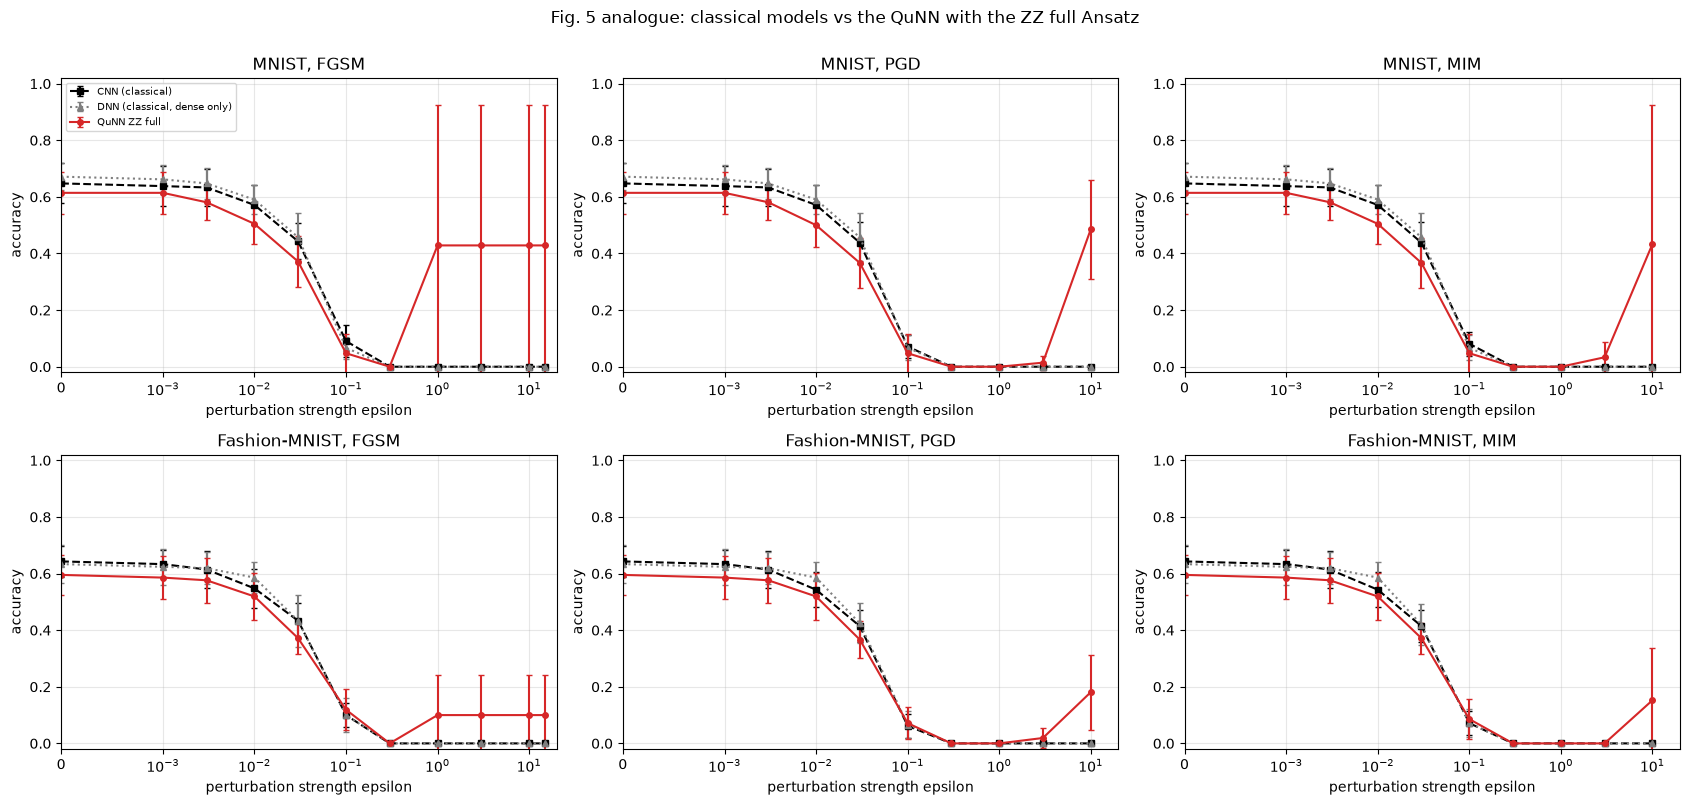

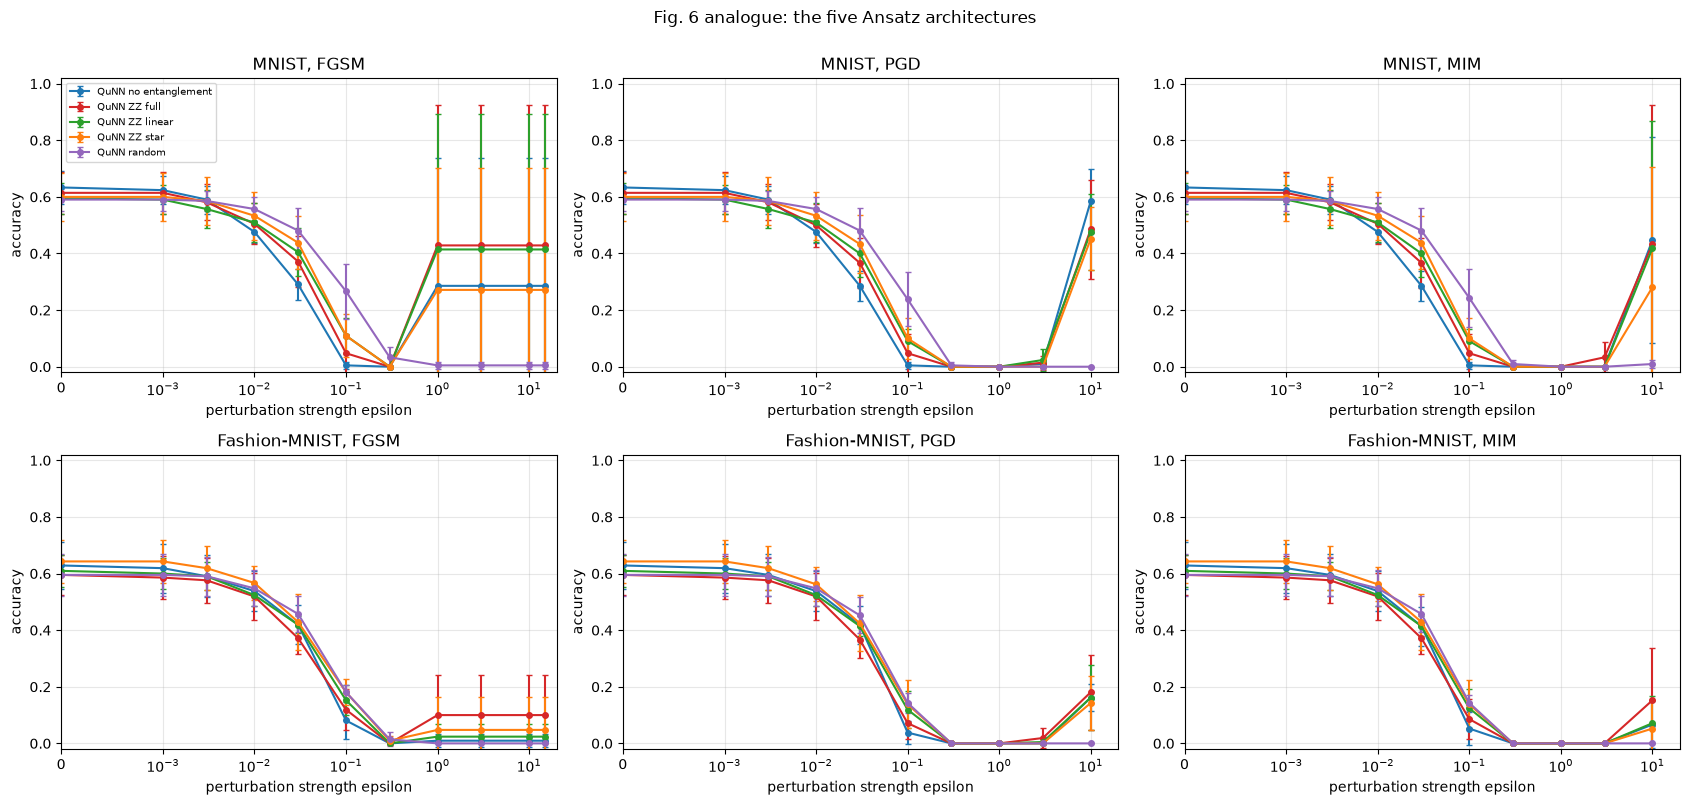

In [17]:
def eps_of(atk): return np.array(FGSM_EPS if atk == "fgsm" else ITER_EPS)
def curve(ds, atk, model):
    a = RES[(ds, model)][atk]; return a.mean(0), a.std(0)
ATKS = [("fgsm", "FGSM"), ("pgd", "PGD"), ("mim", "MIM")]
STYLE = {"CNN": dict(color="k", ls="--", marker="s"), "DNN": dict(color="tab:gray", ls=":", marker="^"), "zz_full": dict(color="tab:red", marker="o"),
         "no_ent": dict(color="tab:blue", marker="o"), "zz_linear": dict(color="tab:green", marker="o"), "zz_star": dict(color="tab:orange", marker="o"), "random": dict(color="tab:purple", marker="o")}
LABEL = {"CNN": "CNN (classical)", "DNN": "DNN (classical, dense only)", "zz_full": "QuNN ZZ full", "no_ent": "QuNN no entanglement", "zz_linear": "QuNN ZZ linear", "zz_star": "QuNN ZZ star", "random": "QuNN random"}

def plot_grid(title, models):
    fig, axes = plt.subplots(2, 3, figsize=(17, 8))
    for r_, ds in enumerate(DATASETS):
        for c_, (atk, an) in enumerate(ATKS):
            ax = axes[r_, c_]
            for k in models:
                mu, sd = curve(ds, atk, k); ax.errorbar(eps_of(atk), mu, sd, ms=4, capsize=2, label=LABEL[k], **STYLE[k])
            ax.set_xscale("symlog", linthresh=1e-3); ax.set_xlim(0, 20); ax.set_ylim(-0.02, 1.02)
            ax.set_xlabel("perturbation strength epsilon"); ax.set_ylabel("accuracy"); ax.set_title(f"{FULL_NAME[ds]}, {an}")
    axes[0, 0].legend(fontsize=7); fig.suptitle(title, y=1.0); plt.tight_layout(); plt.show()

plot_grid("Fig. 5 analogue: classical models vs the QuNN with the ZZ full Ansatz", ["CNN", "DNN", "zz_full"])
plot_grid("Fig. 6 analogue: the five Ansatz architectures", ARCHS)

In [18]:
# numerical table behind the curves (mean over trials): accuracy at selected epsilons
SEL = [0.0, 0.01, 0.1, 0.3, 1.0, 10.0]
for ds in DATASETS:
    for atk, an in ATKS:
        e = eps_of(atk); cols = [list(e).index(s) for s in SEL]
        T = pd.DataFrame({LABEL[k]: [RES[(ds, k)][atk].mean(0)[j] for j in cols] for k in MODELS}, index=[f"eps={s}" for s in SEL]).T
        print(f"{FULL_NAME[ds]}, {an}: mean accuracy over {N_TRIALS} trials ({N_TEST} test images per trial)"); display(T.round(3))

MNIST, FGSM: mean accuracy over 7 trials (30 test images per trial)


,eps=0.0,eps=0.01,eps=0.1,eps=0.3,eps=1.0,eps=10.0
CNN (classical),0.648,0.571,0.090,0.000,0.000,0.000
"DNN (classical, dense only)",0.671,0.590,0.067,0.000,0.000,0.000
QuNN no entanglement,0.633,0.476,0.005,0.000,0.286,0.286
QuNN ZZ full,0.614,0.505,0.048,0.000,0.429,0.429
QuNN ZZ linear,0.595,0.510,0.110,0.000,0.414,0.414
QuNN ZZ star,0.600,0.533,0.110,0.000,0.271,0.271
QuNN random,0.590,0.557,0.267,0.033,0.005,0.005


MNIST, PGD: mean accuracy over 7 trials (30 test images per trial)


,eps=0.0,eps=0.01,eps=0.1,eps=0.3,eps=1.0,eps=10.0
CNN (classical),0.648,0.571,0.071,0.000,0.0,0.000
"DNN (classical, dense only)",0.671,0.590,0.067,0.000,0.0,0.000
QuNN no entanglement,0.633,0.476,0.005,0.000,0.0,0.586
QuNN ZZ full,0.614,0.500,0.048,0.000,0.0,0.486
QuNN ZZ linear,0.595,0.510,0.090,0.000,0.0,0.476
QuNN ZZ star,0.600,0.533,0.100,0.000,0.0,0.452
QuNN random,0.590,0.557,0.238,0.005,0.0,0.000


MNIST, MIM: mean accuracy over 7 trials (30 test images per trial)


...

,eps=0.0,eps=0.01,eps=0.1,eps=0.3,eps=1.0,eps=10.0
CNN (classical),0.643,0.548,0.100,0.000,0.000,0.000
"DNN (classical, dense only)",0.633,0.586,0.100,0.000,0.000,0.000
QuNN no entanglement,0.629,0.538,0.081,0.000,0.010,0.010
QuNN ZZ full,0.595,0.519,0.119,0.000,0.100,0.100
QuNN ZZ linear,0.610,0.524,0.152,0.000,0.024,0.024
QuNN ZZ star,0.643,0.567,0.181,0.010,0.048,0.048
QuNN random,0.595,0.548,0.181,0.014,0.000,0.000


Fashion-MNIST, PGD: mean accuracy over 7 trials (30 test images per trial)


,eps=0.0,eps=0.01,eps=0.1,eps=0.3,eps=1.0,eps=10.0
CNN (classical),0.643,0.543,0.062,0.0,0.0,0.000
"DNN (classical, dense only)",0.633,0.586,0.067,0.0,0.0,0.000
QuNN no entanglement,0.629,0.538,0.038,0.0,0.0,0.162
QuNN ZZ full,0.595,0.519,0.071,0.0,0.0,0.181
QuNN ZZ linear,0.610,0.524,0.119,0.0,0.0,0.162
QuNN ZZ star,0.643,0.562,0.138,0.0,0.0,0.143
QuNN random,0.595,0.548,0.143,0.0,0.0,0.000


Fashion-MNIST, MIM: mean accuracy over 7 trials (30 test images per trial)


,eps=0.0,eps=0.01,eps=0.1,eps=0.3,eps=1.0,eps=10.0
CNN (classical),0.643,0.543,0.071,0.0,0.0,0.000
"DNN (classical, dense only)",0.633,0.586,0.071,0.0,0.0,0.000
QuNN no entanglement,0.629,0.538,0.052,0.0,0.0,0.067
QuNN ZZ full,0.595,0.519,0.086,0.0,0.0,0.152
QuNN ZZ linear,0.610,0.524,0.124,0.0,0.0,0.071
QuNN ZZ star,0.643,0.562,0.138,0.0,0.0,0.052
QuNN random,0.595,0.548,0.143,0.0,0.0,0.000


## 6. Side-by-side comparison with the paper, claim by claim

The paper reports its results as plots and prose, not as tables, so the checks below translate each statement into a rule that can be challenged. The *robustness score* of a model on one panel is its mean accuracy over the non-zero epsilons of the attack, averaged over trials
("low" = 0 < epsilon <= 0.1, "high" = epsilon >= 1, "all" = every non-zero epsilon). **Reproduced** when the rule is satisfied, **not reached** / **exceeded** when a number falls short of / goes beyond the paper's, **cannot be checked** when the paper gives no number.
With 30 test images per trial and 3 to 7 trials a single accuracy has a standard error of roughly 0.03 to 0.05, so only clear differences are meaningful.

In [19]:
def score(ds, atk, model, region="all"):
    eps = eps_of(atk); a = RES[(ds, model)][atk].mean(0)
    sel = (eps > 0) & ((eps <= 0.1 + 1e-9) if region == "low" else (eps >= 1.0 - 1e-9) if region == "high" else True)
    return float(a[sel].mean())

V = []        # (claim, paper, here, verdict, rule)
Q = "zz_full"

# C1: Fig. 5a - MNIST, FGSM: classical models collapse, the ZZ-full QuNN keeps more than 0.6 at high epsilon
hi_q = score("MNIST", "fgsm", Q, "high"); hi_c = {k: score("MNIST", "fgsm", k, "high") for k in ("CNN", "DNN")}
V.append(("Fig. 5a: QuNN (ZZ full) keeps > 0.6 accuracy at high epsilon (MNIST, FGSM)", "> 0.6 at high epsilon", f"QuNN {hi_q:.2f} (mean over epsilon >= 1)",
          "reproduced" if hi_q >= 0.6 else "not reached", "mean accuracy over epsilon >= 1 is at least 0.6"))
V.append(("Fig. 5a: classical models drop to near zero (MNIST, FGSM)", "'near zero at smaller perturbations'", f"CNN {hi_c['CNN']:.2f}, DNN {hi_c['DNN']:.2f} (mean over epsilon >= 1)",
          "reproduced" if max(hi_c.values()) <= 0.15 else "not reached", "both classical models <= 0.15 at epsilon >= 1"))

# C2: QuNN more robust than the classical models, per panel (3 attacks x 2 datasets)
wins = []; panel_txt = []
for ds in DATASETS:
    for atk, an in ATKS:
        s_q, s_c, s_d = score(ds, atk, Q), score(ds, atk, "CNN"), score(ds, atk, "DNN"); wins.append(s_q > max(s_c, s_d))
        panel_txt.append(f"{ds[:5]}/{an}: {s_q:.2f} vs {s_c:.2f}/{s_d:.2f}")
V.append(("QuNN (ZZ full) is more robust than both classical models, all attacks and datasets (Fig. 5, 6)", "QuNN higher in every panel", f"QuNN above both classical models in {sum(wins)}/6 panels; " + "; ".join(panel_txt),
          "reproduced" if sum(wins) >= 5 else "not reached", "robustness score (all epsilon) above both CNN and DNN in >= 5 of 6 panels"))
w_pm = [wins[i] for i in (1, 2, 4, 5)]
V.append(("PGD and MIM: the QuNN is more robust than the classical models", "'same as FGSM' (Fig. 5b, 5c)", f"QuNN above both classical models in {sum(w_pm)}/4 PGD/MIM panels", "reproduced" if sum(w_pm) >= 3 else "not reached", ">= 3 of the 4 PGD/MIM panels"))

# C3: MIM gives a slightly lower QuNN accuracy than PGD
d_pm = np.mean([score(ds, "mim", Q) - score(ds, "pgd", Q) for ds in DATASETS])
V.append(("MIM is slightly stronger than PGD against the QuNN (Fig. 5c)", "'slight decrease in accuracy'", f"mean (MIM score - PGD score) over the two datasets = {d_pm:+.3f}", "reproduced" if -0.10 <= d_pm <= 0.01 else "not reached", "difference between -0.10 and +0.01"))

# C4: Fashion-MNIST level ~0.4 for the QuNN, classical near zero
fm_q = np.mean([score("FMNIST", atk, Q, "high") for atk, _ in ATKS]); fm_c = max(np.mean([score("FMNIST", atk, k, "high") for atk, _ in ATKS]) for k in ("CNN", "DNN"))
V.append(("Fashion-MNIST: QuNN accuracy level around 0.4, classical near zero (Fig. 6a-c)", "QuNN ~ 0.4, classical ~ 0", f"QuNN {fm_q:.2f}, best classical {fm_c:.2f} (mean over attacks, epsilon >= 1)",
          "reproduced" if abs(fm_q - 0.4) <= 0.1 and fm_c <= 0.15 else ("exceeded" if fm_q > 0.5 else "not reached"), "QuNN within 0.1 of 0.4 and best classical <= 0.15"))

# C5: largest accuracy gain over the classical CNN
for ds, claim in (("MNIST", 60), ("FMNIST", 40)):
    best = 0.0
    for atk, an in ATKS:
        for k in ARCHS:
            best = max(best, float((RES[(ds, k)][atk].mean(0) - RES[(ds, "CNN")][atk].mean(0)).max()) * 100)
    v = "reproduced" if abs(best - claim) <= 10 else ("exceeded" if best > claim else "not reached")
    V.append((f"Largest accuracy gain of a QuNN over the CNN, {FULL_NAME[ds]}", f"'up to {claim} %'", f"{best:.1f} percentage points (best architecture, best attack / epsilon)", v, "within 10 points of the paper's figure (reading '% higher robustness' as accuracy points)"))

# C6: Fig. 6d-f - MNIST, ZZ full and ZZ star are the most robust; no_ent and zz_linear beat random
def rank_txt(ds, atk): s = {k: score(ds, atk, k) for k in ARCHS}; return ">".join(sorted(s, key=s.get, reverse=True)), s
top2 = 0; nl_r = 0; txt = []
for atk, an in ATKS:
    o, s = rank_txt("MNIST", atk); txt.append(f"{an}: {o}")
    top2 += set(sorted(s, key=s.get, reverse=True)[:2]) == {"zz_full", "zz_star"}
    nl_r += min(s["no_ent"], s["zz_linear"]) > s["random"]
V.append(("MNIST: ZZ full and ZZ star are the two most robust architectures (Fig. 6d-f)", "top two under all three attacks", f"top-2 = {{ZZ full, ZZ star}} in {top2}/3 attacks; rankings: " + "; ".join(txt),
          "reproduced" if top2 >= 2 else "not reached", "top-2 set is {zz_full, zz_star} in >= 2 of 3 attacks"))
V.append(("MNIST: no-entanglement and ZZ linear beat the random architecture (Fig. 6d-f)", "random 'consistently underperforms'", f"both above random in {nl_r}/3 attacks", "reproduced" if nl_r >= 2 else "not reached", "both above random in >= 2 of 3 attacks"))
ent_w = sum(score("MNIST", a, "zz_full") > score("MNIST", a, "no_ent") for a, _ in ATKS)
V.append(("MNIST: more entanglement (no entanglement -> ZZ full) improves robustness (Section IV-D)", "improved resilience", f"ZZ full above no-entanglement in {ent_w}/3 attacks", "reproduced" if ent_w >= 2 else "not reached", ">= 2 of 3 attacks"))

# C7: Fashion-MNIST - random architecture best (Fig. 6a); ranking differs between datasets
rand_best = 0; txt = []; rho = []
for atk, an in ATKS:
    o, s = rank_txt("FMNIST", atk); txt.append(f"{an}: {o}"); rand_best += max(s, key=s.get) == "random"
    rho.append(spearmanr([s[k] for k in ARCHS], [score("MNIST", atk, k) for k in ARCHS])[0])
V.append(("Fashion-MNIST: the random architecture outperforms the others under FGSM (Fig. 6a)", "random best", f"random best in {rand_best}/3 attacks; rankings: " + "; ".join(txt), "reproduced" if rank_txt("FMNIST", "fgsm")[0].startswith("random") else "not reached", "random has the highest FGSM robustness score"))
V.append(("The robustness ranking of the Ansatzes differs between MNIST and Fashion-MNIST", "'varies between the datasets'", "Spearman correlation between the MNIST and FMNIST rankings per attack: " + ", ".join(f"{x:+.2f}" for x in rho),
          "reproduced" if np.mean(rho) < 0.8 else "not reached", "mean rank correlation < 0.8 (rankings are not the same)"))

# C8: plateau beyond epsilon = 1 for FGSM
mx = 0.0
for ds in DATASETS:
    for k in MODELS:
        a = RES[(ds, k)]["fgsm"]; e = np.array(FGSM_EPS); mx = max(mx, float(np.abs(a[:, e >= 1.0] - a[:, [list(e).index(1.0)]]).max()))
V.append(("FGSM accuracy is constant for epsilon >= 1 (pixel clipping, pointer 4 of Fig. 5a)", "plateau", f"max deviation from the epsilon = 1 value over all models, datasets, trials = {mx:.3f}", "reproduced" if mx <= 0.02 else "not reached", "deviation <= 0.02"))
V.append(("Hardware validation", "none (simulation only)", "-", "cannot be checked", "the paper reports simulator results only"))

VER = pd.DataFrame(V, columns=["claim", "paper", "this notebook", "verdict", "rule"])
pd.set_option("display.max_colwidth", 200, "display.width", 250); display(VER)
print(VER["verdict"].value_counts().to_string())

,claim,paper,this notebook,verdict,rule
0,"Fig. 5a: QuNN (ZZ full) keeps > 0.6 accuracy at high epsilon (MNIST, FGSM)",> 0.6 at high epsilon,QuNN 0.43 (mean over epsilon >= 1),not reached,mean accuracy over epsilon >= 1 is at least 0.6
1,"Fig. 5a: classical models drop to near zero (MNIST, FGSM)",'near zero at smaller perturbations',"CNN 0.00, DNN 0.00 (mean over epsilon >= 1)",reproduced,both classical models <= 0.15 at epsilon >= 1
2,"QuNN (ZZ full) is more robust than both classical models, all attacks and datasets (Fig. 5, 6)",QuNN higher in every panel,QuNN above both classical models in 4/6 panels; MNIST/FGSM: 0.38 vs 0.24/0.24; MNIST/PGD: 0.29 vs 0.26/0.27; MNIST/MIM: 0.29 vs 0.26/0.27; FMNIS/FGSM: 0.26 vs 0.23/0.24; FMNIS/PGD: 0.26 vs 0.25/0....,not reached,robustness score (all epsilon) above both CNN and DNN in >= 5 of 6 panels
3,PGD and MIM: the QuNN is more robust than the classical models,"'same as FGSM' (Fig. 5b, 5c)",QuNN above both classical models in 2/4 PGD/MIM panels,not reached,>= 3 of the 4 PGD/MIM panels
4,MIM is slightly stronger than PGD against the QuNN (Fig. 5c),'slight decrease in accuracy',mean (MIM score - PGD score) over the two datasets = -0.003,reproduced,difference between -0.10 and +0.01
5,"Fashion-MNIST: QuNN accuracy level around 0.4, classical near zero (Fig. 6a-c)","QuNN ~ 0.4, classical ~ 0","QuNN 0.07, best classical 0.00 (mean over attacks, epsilon >= 1)",not reached,QuNN within 0.1 of 0.4 and best classical <= 0.15
6,"Largest accuracy gain of a QuNN over the CNN, MNIST",'up to 60 %',"58.6 percentage points (best architecture, best attack / epsilon)",reproduced,within 10 points of the paper's figure (reading '% higher robustness' as accuracy points)
7,"Largest accuracy gain of a QuNN over the CNN, Fashion-MNIST",'up to 40 %',"18.1 percentage points (best architecture, best attack / epsilon)",not reached,within 10 points of the paper's figure (reading '% higher robustness' as accuracy points)
8,MNIST: ZZ full and ZZ star are the two most robust architectures (Fig. 6d-f),top two under all three attacks,"top-2 = {ZZ full, ZZ star} in 0/3 attacks; rankings: FGSM: zz_full>zz_linear>zz_star>no_ent>random; PGD: zz_star>zz_linear>zz_full>no_ent>random; MIM: zz_full>zz_linear>zz_star>random>no_ent",not reached,"top-2 set is {zz_full, zz_star} in >= 2 of 3 attacks"
9,MNIST: no-entanglement and ZZ linear beat the random architecture (Fig. 6d-f),random 'consistently underperforms',both above random in 2/3 attacks,reproduced,both above random in >= 2 of 3 attacks


verdict
not reached          7
reproduced           7
cannot be checked    1


In [20]:
# a quick look beyond the paper's selected panels: robustness scores of every model (mean accuracy over all non-zero epsilons; low = epsilon <= 0.1; high = epsilon >= 1)
rows = []
for model in MODELS:
    rows.append({"model": LABEL[model], **{f"{ds[:5]} {an} all": round(score(ds, atk, model), 3) for ds in DATASETS for atk, an in ATKS},
                 **{f"{ds[:5]} {an} low": round(score(ds, atk, model, "low"), 3) for ds in DATASETS for atk, an in ATKS}})
display(pd.DataFrame(rows).set_index("model"))

,MNIST FGSM all,MNIST PGD all,MNIST MIM all,FMNIS FGSM all,FMNIS PGD all,FMNIS MIM all,MNIST FGSM low,MNIST PGD low,MNIST MIM low,FMNIS FGSM low,FMNIS PGD low,FMNIS MIM low
model,,,,,,,,,,,,
CNN (classical),0.238,0.261,0.262,0.233,0.252,0.253,0.475,0.470,0.472,0.466,0.453,0.455
"DNN (classical, dense only)",0.242,0.269,0.269,0.236,0.258,0.258,0.485,0.485,0.485,0.472,0.464,0.464
QuNN no entanglement,0.313,0.286,0.270,0.229,0.263,0.254,0.397,0.396,0.396,0.450,0.442,0.444
QuNN ZZ full,0.383,0.290,0.287,0.257,0.258,0.254,0.424,0.422,0.423,0.434,0.424,0.428
QuNN ZZ linear,0.383,0.294,0.285,0.238,0.268,0.258,0.434,0.430,0.430,0.457,0.450,0.450
QuNN ZZ star,0.335,0.301,0.282,0.264,0.281,0.271,0.453,0.450,0.451,0.488,0.477,0.478
QuNN random,0.253,0.273,0.275,0.239,0.259,0.259,0.496,0.490,0.491,0.474,0.466,0.467


## 7. Reading the paper critically

*The numbers quoted here are from the stored full run (`FAST_MODE = False`: 7 trials per dataset, 30 test images per trial, 30 epochs, PGD and MIM with 10 steps). A `FAST_MODE` re-run uses 3 trials and 5 steps and is noisier. With 30 test images and 7 trials the standard error of one accuracy value is about 0.03 to 0.05, so differences of 0.02 to 0.03 between curves are not significant.*

**What the re-run supports.**
* **The classical models collapse.** Under FGSM, PGD and MIM the CNN and the fully-connected network lose most of their accuracy by epsilon = 0.1 and are at exactly 0 for epsilon >= 0.3 (7 trials, both datasets). This part of Figures 5 and 6 is reproduced without any doubt.
* **Some QuNNs "recover" at saturating epsilon under FGSM, and the effect is large.** For epsilon >= 1 the FGSM images are binary (pixels pushed to 0 or 1), the QuNN circuits are periodic in the pixel value, and the first-order gradient direction computed at the clean image no longer increases the loss there. Several QuNN trials then classify **all 30** attacked images correctly (accuracy 1.00) although their clean accuracy is only 0.5 to 0.7, while other trials of the same circuit give 0.00 (see the per-trial table of section 5). The mean over trials (ZZ full on MNIST 0.43, ZZ linear 0.41, no entanglement 0.29, ZZ star 0.27; the classical models 0.00) reproduces the *direction* of the paper's "QuNN keeps accuracy at large epsilon" and a gain of 58.6 accuracy points over the CNN on MNIST, close to the abstract's "up to 60 %". But this is a bimodal, trial-dependent effect with huge error bars, not a smooth robustness gain, and under PGD and MIM, whose iterative steps re-linearise the loss, accuracy is 0 for every epsilon from 0.3 to 1 and the same recovery appears only at the very largest epsilon (epsilon = 10: MNIST 0.45 to 0.59 for PGD and 0.28 to 0.45 for MIM, Fashion-MNIST 0.05 to 0.18, for all QuNNs except the random circuit). A white-box attacker that simply uses a smaller epsilon or an iterative attack is not stopped by it; it is best read as a failure of the one-step gradient attack on a non-monotone feature map (a form of gradient masking), which the paper itself hints at when it says the QuNN "retains accuracy even at larger epsilon" but does not test.
* **Statements that need only qualitative support.** MIM is as strong as or marginally stronger than PGD (mean score difference -0.003), accuracy is exactly constant for epsilon >= 1 under FGSM (clipping), the Ansatz ranking is not the same on MNIST and Fashion-MNIST (rank correlations +0.3, +0.7, +0.1), and on MNIST ZZ full beats the no-entanglement circuit under all three attacks (0.38 vs 0.31, 0.29 vs 0.29, 0.29 vs 0.27; only the FGSM difference is outside the noise, and it is driven by the saturation effect above).

**What the re-run does not support.**
* **QuNN robustness at *small and medium* epsilon.** For 0 < epsilon <= 0.1 the QuNNs are no better than the classical models (mean accuracy 0.40 to 0.50 against 0.47 to 0.49 for the CNN/DNN, with the random circuit nominally highest on MNIST at 0.50). The paper's pointer 1 ("higher accuracy at low perturbations") is not reproduced, and the claim that the CNN/DNN "reach near zero at smaller perturbations" than the QuNN is true only in the saturated FGSM regime.
* **The architecture ranking.** The paper finds ZZ full and ZZ star to be the two most robust circuits on MNIST under all three attacks; here the top two are {ZZ full, ZZ linear} (FGSM), {ZZ star, ZZ linear} (PGD) and {ZZ full, ZZ linear} (MIM), and the random circuit is not "consistently the worst" (it is the worst for FGSM at saturation, but the best at epsilon <= 0.1). On Fashion-MNIST the paper's claim that the random circuit is best is not reproduced: ZZ star is best under all three attacks (0.26 to 0.28 against 0.24 to 0.26 for random), and the QuNN level "around 0.4" at high epsilon is not reached (0.07). The largest Fashion-MNIST gain over the CNN is 18 points, not 40.
* **Why the random circuit differs.** A random circuit that leaves a qubit with only `RZ` gates after the encoding makes that channel independent of its pixel; such pixels have exactly zero gradient (about 40 to 80 % of the pixel gradients in our random circuits), so FGSM cannot move them. This is a property of the particular random draw and explains the very different behaviour of the random architecture (no saturation recovery, nominally better at low epsilon), but also why a single "random architecture" curve is hard to interpret; the paper does not say how its random circuit is built.

**Why numbers can differ from the paper.** The paper does not give the random-circuit definition, the quantum-angle distribution (we use uniform in [0, 2 pi), a new draw per trial), the PGD/MIM step size and iteration count, the MIM decay factor, the exact epsilon grid, the selection of the 50 training and 30 test images, or the clean accuracies; the code is not public. Clean accuracies here are about 0.6 to 0.67 for all models (50 training images, learning rate 0.001, 30 epochs); the paper's figures were not available as numbers. With only 30 test images the accuracy of one trial moves in steps of 0.033, and the conclusions above rest on 7 trials; the saturation effect in particular is a coin-flip per trial and circuit.

**What the notebook adds.** A per-trial table of the saturation accuracy, an exact analytic input gradient verified by finite differences, an assertion that the NumPy simulator and the PennyLane QNode agree to 1e-15, RandomForest / SVC baselines on the same inputs, and verdict rules written next to every claim.

## Exercises

1. **More trials, more test images.** With 30 test images and 7 trials the error bars of the paper (and of this notebook) are large. Raise `N_TEST` to 300 and `N_TRIALS` to 20 and re-run the architecture comparison of Figure 6: which of the paper's rankings survive?
2. **Train the quantum layer.** The paper freezes the quanvolution filter. Add the derivative with respect to the circuit angles (parameter-shift rule, or use PennyLane's autodiff on `make_qnode`) and train them as well. Does the ranking of the five architectures change, and does the QuNN stay more robust than the CNN?
3. **A gradient-free attack.** Replace FGSM by a random-sign perturbation or a few hundred random restarts at the same epsilon. If the QuNN's advantage disappears, how much of it was gradient masking by the small output range of `<Z>`?
4. **Other encodings.** Replace `RY(pi x)` by `RY(x)` (angles in [0, 1] rad, as in the related RobQuNN papers) in `product_state`/`Quanv`. How does the smaller angle range change the robustness of every architecture?
5. **A stronger PGD.** Use 40 steps with a random start and report how much the accuracy of the QuNN and of the CNN drops compared with the 10-step PGD used here. Also vary the momentum `MIM_MU` between 0 and 1.5.